In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate
import psycopg2
import matplotlib.gridspec as gridspec

conn = psycopg2.connect(
    host="localhost",
    port=5432,
    dbname="pro2d_db",
    user="postgres",
    password="postgres"
)

df = pd.read_sql("SELECT * FROM events", conn)
conn.close()

print("=== Spalten im DataFrame ===")
print(df.columns.tolist())
print(f"\nZeilen: {len(df)}, Spalten: {len(df.columns)}")

=== Spalten im DataFrame ===
['Datum', 'Prio', 'Msr', 'Ort', 'Objekt', 'Meldung', 'Zustand', 'Benutzer', 'evtID', 'evtTyp']

Zeilen: 109486, Spalten: 10


/var/folders/7x/4_7qkdl52m1f6f0kqw0hc6yw0000gn/T/ipykernel_2671/1851828955.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT * FROM events", conn)


In [2]:
# Wie oft kommen evtIDs mehrfach vor?
id_counts = df["evtID"].value_counts()
print(f"evtIDs die nur 1x vorkommen: {(id_counts == 1).sum()}")
print(f"evtIDs die >1x vorkommen:    {(id_counts > 1).sum()}")
print(f"\nTop 10 häufigste evtIDs:")
print(id_counts.head(10).to_string())

# Beispiel: Was steckt hinter einer mehrfachen evtID?
top_id = id_counts.index[0]
print(f"\nBeispiel evtID {top_id}:")
print(df[df["evtID"] == top_id][["Datum", "Msr", "Objekt", "Meldung", "Zustand", "Benutzer", "evtTyp"]].head(10).to_string())

evtIDs die nur 1x vorkommen: 25861
evtIDs die >1x vorkommen:    23844

Top 10 häufigste evtIDs:
evtID
975669    6
975169    6
974662    6
973659    6
970506    6
970009    6
969510    6
968011    6
998186    5
976111    5

Beispiel evtID 975669:
                        Datum       Msr                           Objekt                                         Meldung      Zustand Benutzer         evtTyp
56432 2024-10-14 06:12:30.494  QISA-428  Leitwert nach Enthärtungsanlage  Drahtbruch - Messbereich um 10% unterschritten     Freigabe     AUTO  Störmeldungen
56433 2024-10-14 06:12:30.493  QISA-428  Leitwert nach Enthärtungsanlage  Drahtbruch - Messbereich um 10% unterschritten  Quittierung     AUTO  Störmeldungen
56434 2024-10-14 06:12:30.494  QISA-428  Leitwert nach Enthärtungsanlage  Drahtbruch - Messbereich um 10% unterschritten     Freigabe     AUTO  Störmeldungen
56435 2024-10-14 06:12:30.493  QISA-428  Leitwert nach Enthärtungsanlage  Drahtbruch - Messbereich um 10% unterschritten  

In [3]:
# === Datum Analyse ===
datum_counts = df["Datum"].value_counts()
print(f"Datums die nur 1x vorkommen: {(datum_counts == 1).sum()}")
print(f"Datums die >1x vorkommen:    {(datum_counts > 1).sum()}")
print(f"\nTop 10 häufigste Zeitstempel:")
print(datum_counts.head(10).to_string())

top_datum = datum_counts.index[0]
print(f"\nBeispiel Datum {top_datum}:")
print(df[df["Datum"] == top_datum][["Datum", "Msr", "Objekt", "Meldung", "Zustand", "Benutzer", "evtTyp"]].to_string())

Datums die nur 1x vorkommen: 84566
Datums die >1x vorkommen:    8622

Top 10 häufigste Zeitstempel:
Datum
2025-12-04 13:59:22.882    80
2025-12-04 15:18:31.830    69
2025-12-04 13:59:15.530    63
2025-12-04 13:59:15.357    59
2025-12-04 15:18:31.667    55
2025-11-21 10:15:35.022    46
2024-06-18 16:22:29.415    40
2024-06-18 16:22:29.102    40
2025-11-19 13:43:38.923    37
2025-12-04 15:20:02.782    37

Beispiel Datum 2025-12-04 13:59:22.882000:
                        Datum        Msr                                  Objekt                                         Meldung Zustand Benutzer         evtTyp
30917 2025-12-04 13:59:22.882    MI-156b                Feuchte Abluft Messung 2     Überlauf - Messbereich um 10% überschritten    Geht      NaN  Störmeldungen
30918 2025-12-04 13:59:22.882  TIZA-164b                  Temp. Abluft Messung 2                          Oberer Grenzwert Alarm    Geht      NaN  Störmeldungen
30919 2025-12-04 13:59:22.882  TIZA-164b                  Temp. Abl

In [4]:
for col in ["Prio", "Msr", "Ort", "Objekt", "Meldung", "Zustand", "Benutzer", "evtTyp", "Datum", "evtID"]:
    print(f"\n{'='*40}")
    print(f"Spalte: {col}")
    print(f"Anzahl unique: {df[col].nunique(dropna=False)}")
    print(f"{'='*40}")
    print(df[col].unique())


Spalte: Prio
Anzahl unique: 4
[ 0. nan  1.  2.]

Spalte: Msr
Anzahl unique: 494
<StringArray>
[     'MI-156',           nan,   'PARA-3007',   'UV100-D04',      'PRG-16',
   'QIZA-176a',    'QIZA-176',      'V-004C',      'PRG-43',      'PRG-42',
 ...
      'TT-553',      'TT-552',      'SV-105',   'PARA-0302',      'PT-551',
      'PT-553',      'FT-553',      'PT-552', 'UV100-F8023',     'PD-003A']
Length: 494, dtype: str

Spalte: Ort
Anzahl unique: 87
<StringArray>
[                     'Trockner',                             nan,
                 'Hauptprogramm',                 'Schlammabfuhr',
                'Granulatbunker',              'Abluftbehandlung',
                'Schlammeintrag',                 'Schwenkpresse',
                 'Hilfsbetriebe',                           'SEA',
            'Filter Steuergerät',              'Absaugung Filter',
                        'Brüden',                  'Hauptprogram',
                   'Kuehlwasser',                   'Pumpe

Vincenzo Signorelli und Vinzenzo Signorelli kommen vor. Wir definieren Vincenzo als korrekt.

In [5]:
df["Benutzer"] = df["Benutzer"].replace("Vinzenzo Signorelli", "Vincenzo Signorelli")

user_list = df["Benutzer"].fillna("NaN").value_counts().index.tolist()
PALETTE = ["#2563EB", "#DC2626", "#16A34A", "#F59E0B", "#8B5CF6",
           "#EC4899", "#0891B2", "#EA580C", "#4B5563", "#6D28D9",
           "#059669", "#D97706", "#7C3AED", "#BE185D", "#0D9488"]
user_colors = {b: PALETTE[i % len(PALETTE)] for i, b in enumerate(user_list)}
user_list_rev = user_list[::-1]

df_no_login = df[df["evtTyp"] != "Login/Logout"]
df_filtered = df_no_login[
    (df["Benutzer"].notna()) & (~df["Benutzer"].isin(["AUTO"]))
]

all_evt_types = sorted(df["evtTyp"].dropna().unique())
cmap_evt = plt.cm.tab10
evt_colors = {col: cmap_evt(i) for i, col in enumerate(all_evt_types)}

print(f"Benutzer: {user_list}")
print(df["Benutzer"].value_counts(dropna=False))

Benutzer: ['NaN', 'AUTO', 'Roland Reinle', 'Rolf Hirt', 'Daniel Wymann', 'Vincenzo Signorelli', 'Sven Keller', 'Alois Mühlebach', 'Rolf Balz', 'Urs Wenzinger', 'Raphael Brunner', 'Patric Mattig', 'EKAG', 'cag', 'Reto Balz', 'Gast']
Benutzer
NaN                    47767
AUTO                   20721
Roland Reinle          11279
Rolf Hirt              10679
Daniel Wymann           6756
Vincenzo Signorelli     4585
Sven Keller             2719
Alois Mühlebach         2406
Rolf Balz                736
Urs Wenzinger            585
Raphael Brunner          551
Patric Mattig            417
EKAG                     109
cag                       98
Reto Balz                 74
Gast                       4
Name: count, dtype: int64


/var/folders/7x/4_7qkdl52m1f6f0kqw0hc6yw0000gn/T/ipykernel_2671/767811743.py:11: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_filtered = df_no_login[


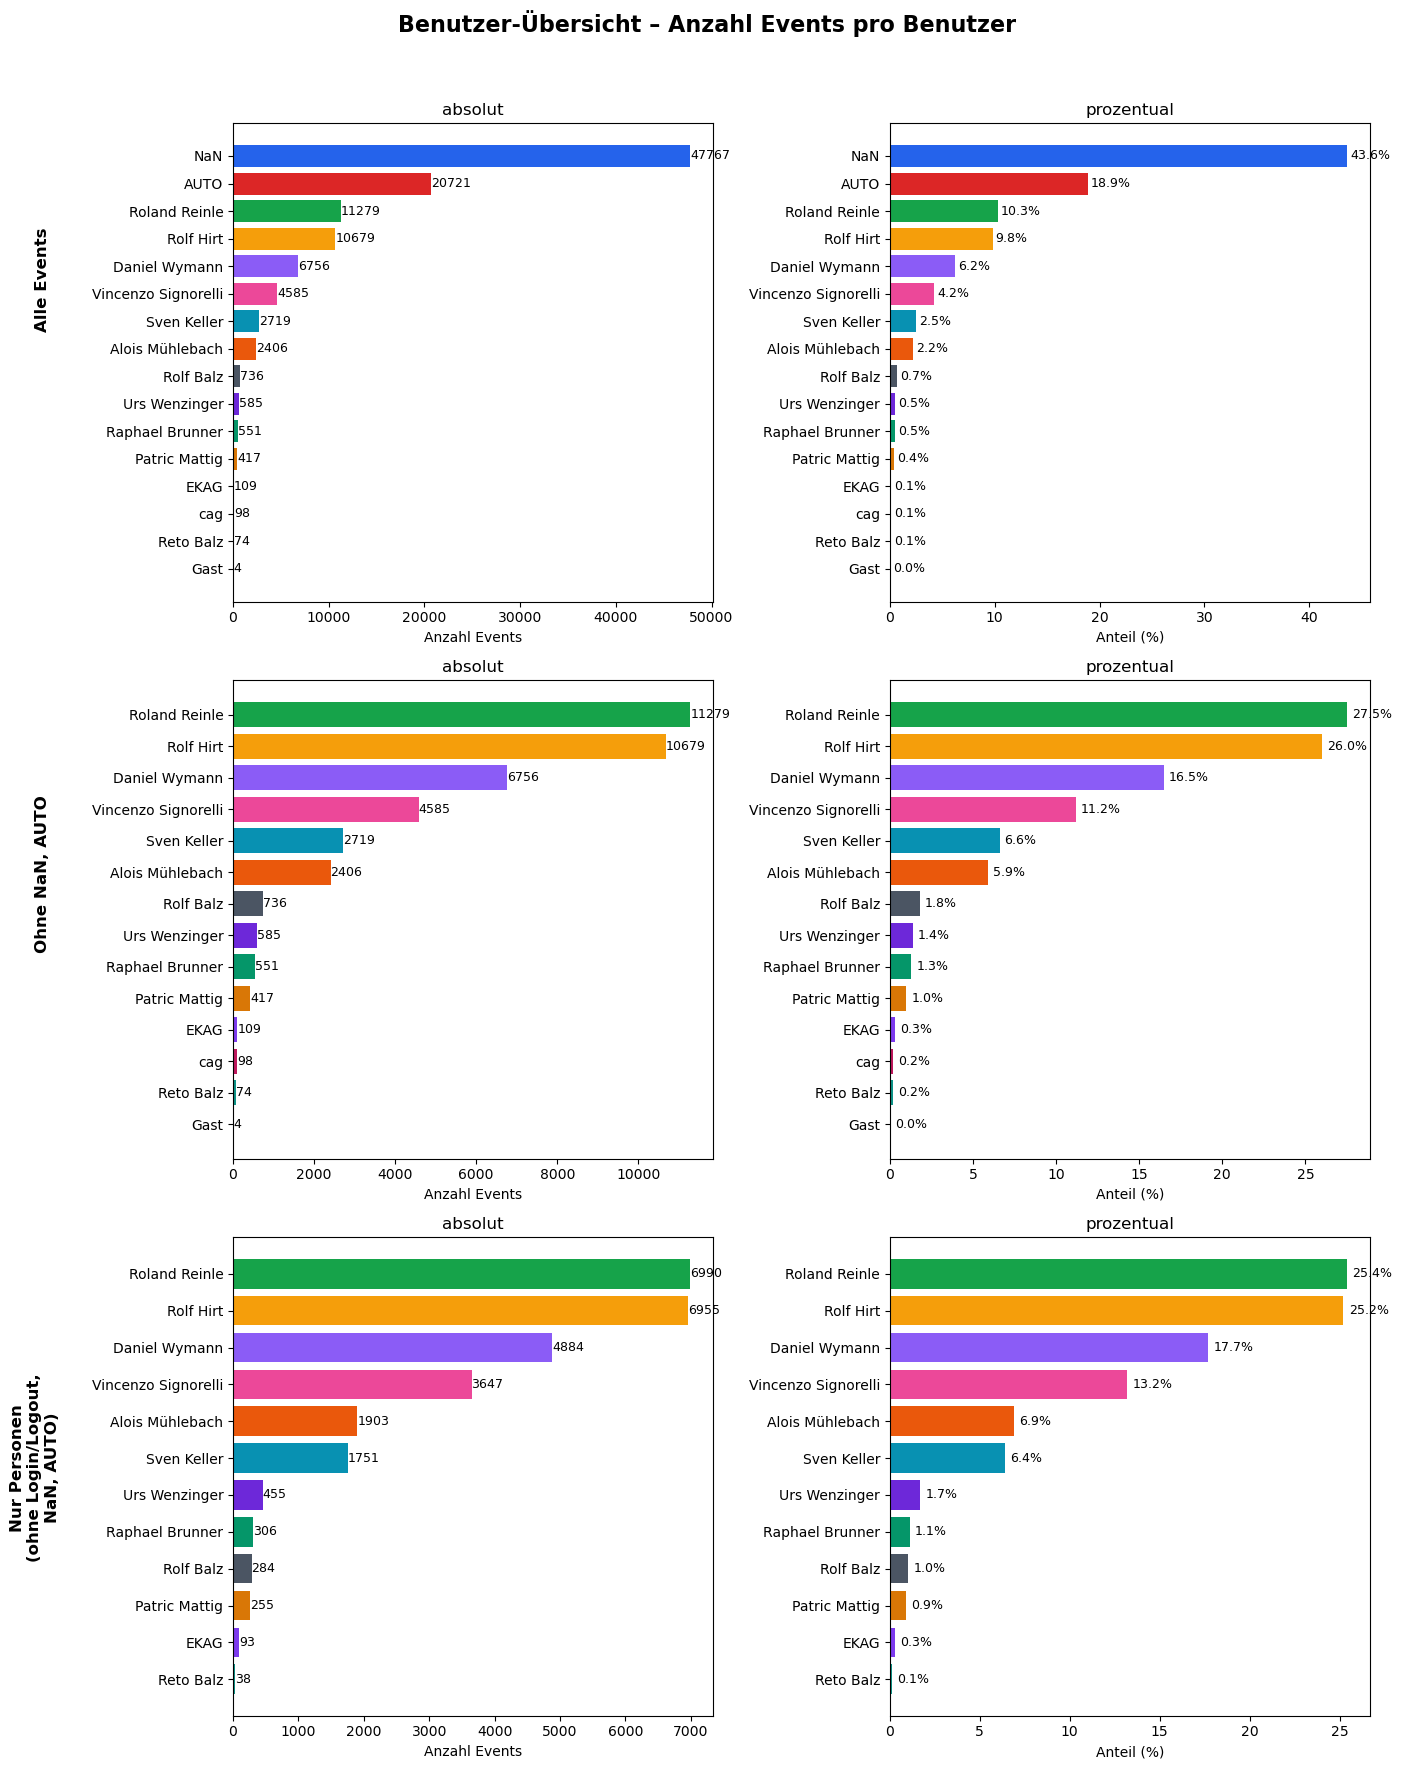

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

# --- Plot 1: Alle Benutzer ---
user_counts = df["Benutzer"].fillna("NaN").value_counts()
bars = axes[0, 0].barh(user_counts.index, user_counts.values,
                        color=[user_colors[b] for b in user_counts.index])
for bar, val in zip(bars, user_counts.values):
    axes[0, 0].text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                     str(val), va="center", fontsize=9)
axes[0, 0].set_xlabel("Anzahl Events")
axes[0, 0].set_title("absolut")
axes[0, 0].invert_yaxis()

user_pct = (user_counts / user_counts.sum() * 100).round(1)
bars2 = axes[0, 1].barh(user_pct.index, user_pct.values,
                         color=[user_colors[b] for b in user_pct.index])
for bar, val in zip(bars2, user_pct.values):
    axes[0, 1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                     f"{val}%", va="center", fontsize=9)
axes[0, 1].set_xlabel("Anteil (%)")
axes[0, 1].set_title("prozentual")
axes[0, 1].invert_yaxis()

# --- Plot 2: Ohne NaN und AUTO ---
df_no_nan_auto = df[(df["Benutzer"].notna()) & (~df["Benutzer"].isin(["AUTO"]))]
user_counts_na = df_no_nan_auto["Benutzer"].value_counts()
bars = axes[1, 0].barh(user_counts_na.index, user_counts_na.values,
                        color=[user_colors[b] for b in user_counts_na.index])
for bar, val in zip(bars, user_counts_na.values):
    axes[1, 0].text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                     str(val), va="center", fontsize=9)
axes[1, 0].set_xlabel("Anzahl Events")
axes[1, 0].set_title("absolut")
axes[1, 0].invert_yaxis()

user_pct_na = (user_counts_na / user_counts_na.sum() * 100).round(1)
bars2 = axes[1, 1].barh(user_pct_na.index, user_pct_na.values,
                         color=[user_colors[b] for b in user_pct_na.index])
for bar, val in zip(bars2, user_pct_na.values):
    axes[1, 1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                     f"{val}%", va="center", fontsize=9)
axes[1, 1].set_xlabel("Anteil (%)")
axes[1, 1].set_title("prozentual")
axes[1, 1].invert_yaxis()

# --- Plot 3: Ohne Login/Logout, NaN, AUTO ---
user_counts_f = df_filtered["Benutzer"].value_counts()
bars = axes[2, 0].barh(user_counts_f.index, user_counts_f.values,
                        color=[user_colors[b] for b in user_counts_f.index])
for bar, val in zip(bars, user_counts_f.values):
    axes[2, 0].text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                     str(val), va="center", fontsize=9)
axes[2, 0].set_xlabel("Anzahl Events")
axes[2, 0].set_title("absolut")
axes[2, 0].invert_yaxis()

user_pct_f = (user_counts_f / user_counts_f.sum() * 100).round(1)
bars2 = axes[2, 1].barh(user_pct_f.index, user_pct_f.values,
                         color=[user_colors[b] for b in user_pct_f.index])
for bar, val in zip(bars2, user_pct_f.values):
    axes[2, 1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                     f"{val}%", va="center", fontsize=9)
axes[2, 1].set_xlabel("Anteil (%)")
axes[2, 1].set_title("prozentual")
axes[2, 1].invert_yaxis()

# Zeilentitel links
fig.text(0.02, 0.83, "Alle Events", fontsize=12, fontweight="bold", rotation=90, va="center")
fig.text(0.02, 0.50, "Ohne NaN, AUTO", fontsize=12, fontweight="bold", rotation=90, va="center")
fig.text(0.02, 0.17, "Nur Personen\n(ohne Login/Logout,\nNaN, AUTO)", fontsize=12, fontweight="bold", rotation=90, va="center", ha="center")

plt.suptitle("Benutzer-Übersicht – Anzahl Events pro Benutzer", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0.05, 0, 1, 0.96])
plt.show()

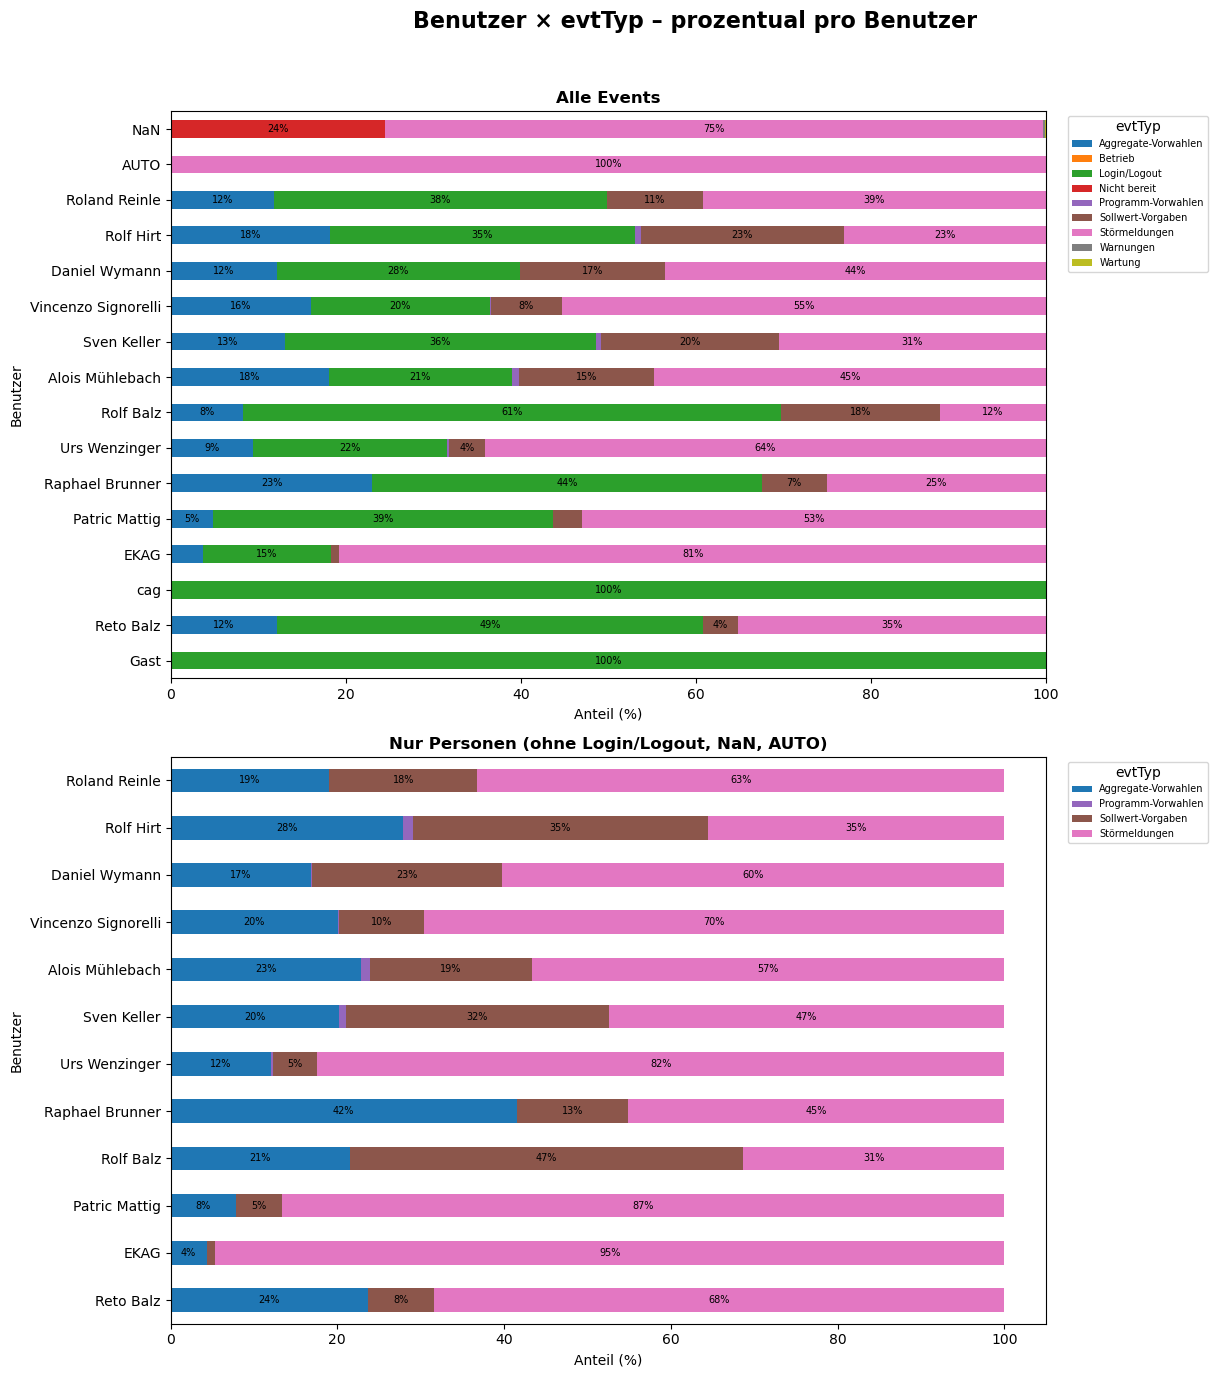

In [7]:
cmap_evt = plt.cm.tab10
all_evt_types = sorted(df["evtTyp"].dropna().unique())
evt_colors = {col: cmap_evt(i) for i, col in enumerate(all_evt_types)}

df_no_nan_auto = df[(df["Benutzer"].notna()) & (~df["Benutzer"].isin(["AUTO"]))]
df_filtered = df_no_nan_auto[df_no_nan_auto["evtTyp"] != "Login/Logout"]

fig, axes = plt.subplots(2, 1, figsize=(14, 14))

datasets = [
    (df, "Alle Events"),
    (df_filtered, "Nur Personen (ohne Login/Logout, NaN, AUTO)")
]

for ax, (data, title) in zip(axes, datasets):
    ct = pd.crosstab(data["Benutzer"].fillna("NaN"), data["evtTyp"].fillna("NaN"))
    ct = ct.reindex(columns=[c for c in all_evt_types if c in ct.columns], fill_value=0)
    user_order = ct.sum(axis=1).sort_values(ascending=True).index

    ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100
    ct_norm.loc[user_order].plot(
        kind="barh", stacked=True, ax=ax,
        color=[evt_colors[c] for c in ct.columns]
    )
    for container in ax.containers:
        lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
        ax.bar_label(container, labels=lbl, label_type="center", fontsize=7)
    ax.set_xlabel("Anteil (%)")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.legend(title="evtTyp", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)

plt.suptitle("Benutzer × evtTyp – prozentual pro Benutzer",
             fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 0.88, 0.96])
plt.show()

/var/folders/7x/4_7qkdl52m1f6f0kqw0hc6yw0000gn/T/ipykernel_2671/2537640535.py:112: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


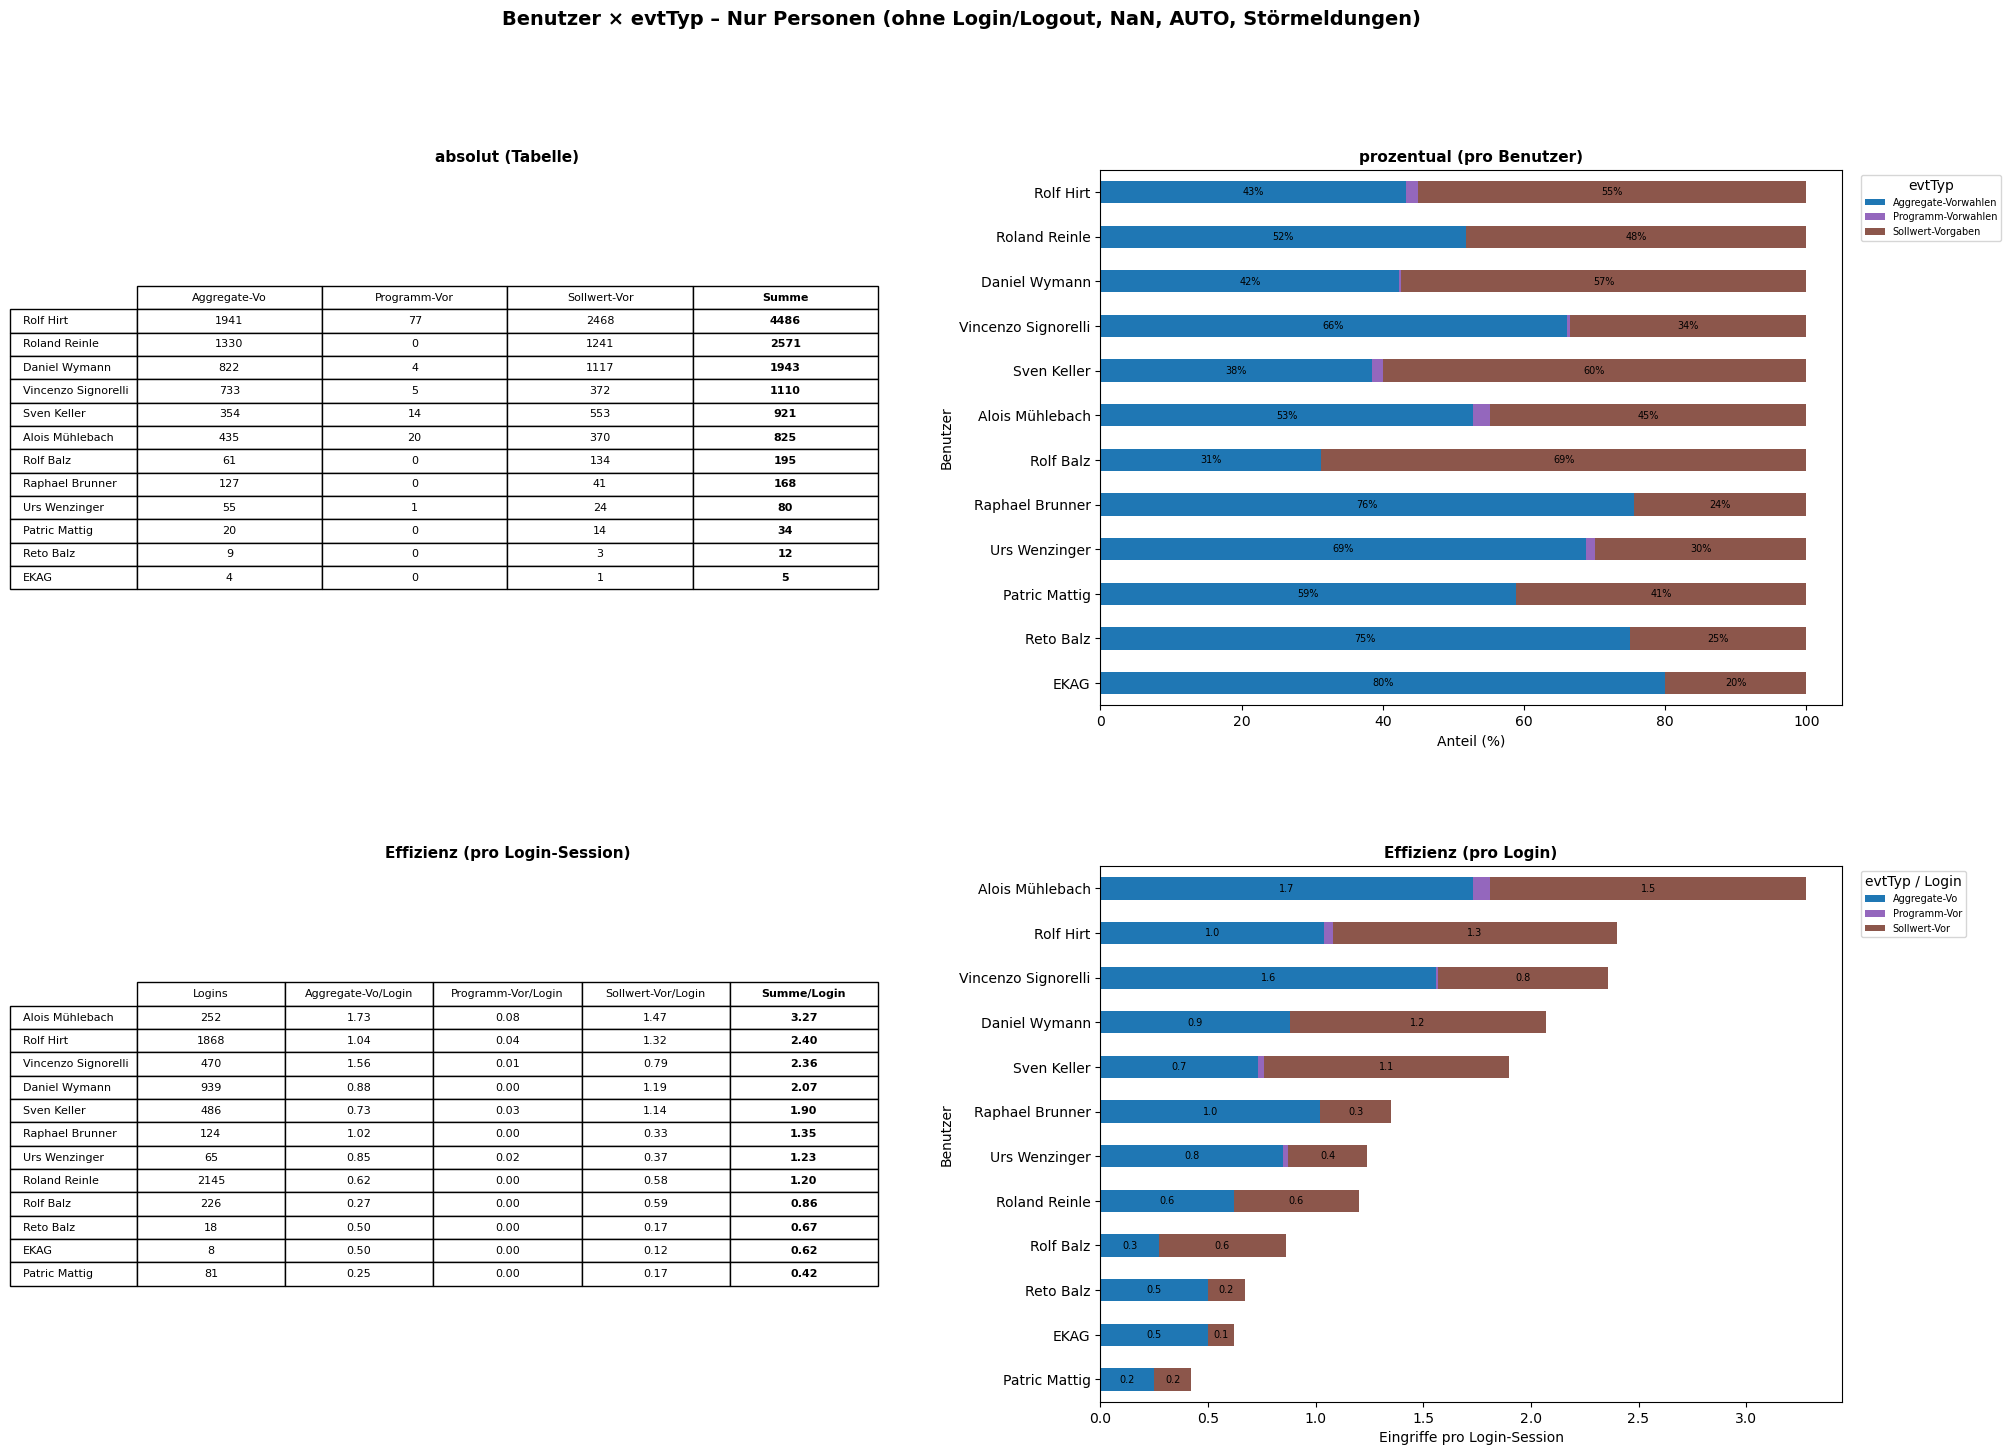

In [8]:
df_persons = df[
    (df["Benutzer"].notna()) &
    (~df["Benutzer"].isin(["AUTO"])) &
    (df["evtTyp"] != "Login/Logout") &
    (df["evtTyp"] != "Störmeldungen")
]

ct = pd.crosstab(df_persons["Benutzer"], df_persons["evtTyp"])
ct = ct.reindex(columns=[c for c in all_evt_types if c in ct.columns], fill_value=0)
ct["Summe"] = ct.sum(axis=1)
user_order_desc = ct["Summe"].sort_values(ascending=False).index
user_order_asc = ct["Summe"].sort_values(ascending=True).index

# Login-Daten
ll = df[df["evtTyp"] == "Login/Logout"]
logins = ll[ll["Meldung"].str.startswith("Login", na=False)]
login_counts = logins.groupby("Benutzer").size().rename("Logins")

# Effizienz berechnen
ct_eff = ct.join(login_counts, how="left")
ct_eff["Logins"] = ct_eff["Logins"].fillna(0).astype(int)
evt_cols = [c for c in ct.columns if c != "Summe"]
for col in evt_cols + ["Summe"]:
    ct_eff[f"{col}/Login"] = (ct_eff[col] / ct_eff["Logins"].replace(0, float("nan"))).round(2)

# Sortierung für Effizienz-Plots
eff_order_desc = ct_eff["Summe/Login"].sort_values(ascending=False).dropna().index
eff_order_asc = ct_eff["Summe/Login"].sort_values(ascending=True).dropna().index

fig = plt.figure(figsize=(22, 16))
gs = gridspec.GridSpec(2, 2, hspace=0.3, wspace=0.3)

# === OBEN LINKS: Tabelle absolut ===
ax_tab1 = fig.add_subplot(gs[0, 0])
ax_tab1.axis("off")
cell_text = ct.loc[user_order_desc].values.astype(int).tolist()
table1 = ax_tab1.table(
    cellText=cell_text,
    rowLabels=user_order_desc.tolist(),
    colLabels=[c[:12] for c in ct.columns],
    cellLoc="center",
    loc="center"
)
table1.auto_set_font_size(False)
table1.set_fontsize(8)
table1.scale(1, 1.4)
summe_col = len(ct.columns) - 1
for row_idx in range(len(cell_text) + 1):
    table1[row_idx, summe_col].set_text_props(fontweight="bold")
ax_tab1.set_title("absolut (Tabelle)", fontsize=11, fontweight="bold")

# === OBEN RECHTS: Stacked Bar prozentual ===
ax_bar1 = fig.add_subplot(gs[0, 1])
ct_plot = ct.drop(columns="Summe")
ct_norm = ct_plot.div(ct_plot.sum(axis=1), axis=0) * 100
ct_norm.loc[user_order_asc].plot(
    kind="barh", stacked=True, ax=ax_bar1,
    color=[evt_colors[c] for c in ct_plot.columns]
)
for container in ax_bar1.containers:
    lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
    ax_bar1.bar_label(container, labels=lbl, label_type="center", fontsize=7)
ax_bar1.set_xlabel("Anteil (%)")
ax_bar1.set_title("prozentual (pro Benutzer)", fontsize=11, fontweight="bold")
ax_bar1.legend(title="evtTyp", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)

# === UNTEN LINKS: Tabelle Effizienz (sortiert nach Summe/Login desc) ===
ax_tab2 = fig.add_subplot(gs[1, 0])
ax_tab2.axis("off")
eff_col_labels = ["Logins"] + [f"{c[:12]}/Login" for c in evt_cols] + ["Summe/Login"]
eff_data = ct_eff.loc[eff_order_desc]
cell_text2 = []
for _, row in eff_data.iterrows():
    r = [int(row["Logins"])]
    r += [f"{row[f'{c}/Login']:.2f}" if not pd.isna(row[f'{c}/Login']) else "-" for c in evt_cols]
    r.append(f"{row['Summe/Login']:.2f}" if not pd.isna(row["Summe/Login"]) else "-")
    cell_text2.append(r)

table2 = ax_tab2.table(
    cellText=cell_text2,
    rowLabels=eff_order_desc.tolist(),
    colLabels=eff_col_labels,
    cellLoc="center",
    loc="center"
)
table2.auto_set_font_size(False)
table2.set_fontsize(8)
table2.scale(1, 1.4)
last_col = len(eff_col_labels) - 1
for row_idx in range(len(cell_text2) + 1):
    table2[row_idx, last_col].set_text_props(fontweight="bold")
ax_tab2.set_title("Effizienz (pro Login-Session)", fontsize=11, fontweight="bold")

# === UNTEN RECHTS: Stacked Bar Effizienz (höchste oben) ===
ax_bar2 = fig.add_subplot(gs[1, 1])
eff_plot_cols = [f"{c}/Login" for c in evt_cols]
plot_eff = ct_eff.loc[eff_order_asc][eff_plot_cols].dropna()
plot_eff.plot(
    kind="barh", stacked=True, ax=ax_bar2,
    color=[evt_colors.get(c, "grey") for c in evt_cols]
)
for container in ax_bar2.containers:
    lbl = [f"{v.get_width():.1f}" if v.get_width() > 0.1 else "" for v in container]
    ax_bar2.bar_label(container, labels=lbl, label_type="center", fontsize=7)
ax_bar2.set_xlabel("Eingriffe pro Login-Session")
ax_bar2.legend([c[:12] for c in evt_cols],
               title="evtTyp / Login", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
ax_bar2.set_title("Effizienz (pro Login)", fontsize=11, fontweight="bold")

plt.suptitle("Benutzer × evtTyp – Nur Personen (ohne Login/Logout, NaN, AUTO, Störmeldungen)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [9]:
ll = df[df["evtTyp"] == "Login/Logout"]
logins = ll[ll["Meldung"].str.startswith("Login", na=False)]
logouts = ll[ll["Meldung"].str.startswith("Logout", na=False)]

print("=== Login/Logout Symmetrie pro Benutzer ===")
print(f"{'Benutzer':<25} {'Logins':>8} {'Logouts':>8} {'Differenz':>10}")
print("=" * 55)

all_ll_users = set(logins["Benutzer"].dropna().unique()) | set(logouts["Benutzer"].dropna().unique())
for user in sorted(all_ll_users):
    n_login = len(logins[logins["Benutzer"] == user])
    n_logout = len(logouts[logouts["Benutzer"] == user])
    diff = n_login - n_logout
    marker = " !!!" if diff != 0 else ""
    print(f"{user:<25} {n_login:>8} {n_logout:>8} {diff:>10}{marker}")

total_l = len(logins)
total_o = len(logouts)
print(f"\n{'TOTAL':<25} {total_l:>8} {total_o:>8} {total_l - total_o:>10}")

=== Login/Logout Symmetrie pro Benutzer ===
Benutzer                    Logins  Logouts  Differenz
Alois Mühlebach                252      251          1 !!!
Daniel Wymann                  939      933          6 !!!
EKAG                             8        8          0
Gast                             2        2          0
Patric Mattig                   81       81          0
Raphael Brunner                124      121          3 !!!
Reto Balz                       18       18          0
Roland Reinle                 2145     2144          1 !!!
Rolf Balz                      226      226          0
Rolf Hirt                     1868     1856         12 !!!
Sven Keller                    486      482          4 !!!
Urs Wenzinger                   65       65          0
Vincenzo Signorelli            470      468          2 !!!
cag                             49       49          0

TOTAL                         6733     6704         29


In [10]:
eingriffe = df[df["evtTyp"].isin([
    "Sollwert-Vorgaben",
    "Aggregate-Vorwahlen",
    "Programm-Vorwahlen"
])]

for evt in ["Sollwert-Vorgaben", "Aggregate-Vorwahlen", "Programm-Vorwahlen"]:
    subset = eingriffe[eingriffe["evtTyp"] == evt]
    combos = subset.groupby(["Msr", "Ort", "Objekt"]).size().reset_index(name="Anzahl")
    combos = combos.sort_values("Anzahl", ascending=False)
    
    print(f"\n{'='*80}")
    print(f"evtTyp: {evt}  ({len(subset)} Zeilen, {len(combos)} unique Kombinationen)")
    print(f"{'='*80}")
    print(combos.to_string(index=False))


evtTyp: Sollwert-Vorgaben  (6338 Zeilen, 279 unique Kombinationen)
        Msr                     Ort                                                       Objekt  Anzahl
  PARA-3515                     SEA                                     Sollwert Schneckenpresse    1254
  PARA-3007           Hauptprogramm                                Vorwahl 'Globale Alarmgruppe'    1016
   PID-4300              Verteiler                                             Drehzahl Dosierer     426
  PARA-3507                     SEA                                                Start / Stop      296
  PARA-2023         Schlammtrockner                               Drehzahl Dosierer obere Grenze     243
  PARA-2300           Hauptprogramm                                           Bedienung Trockner     241
  PARA-3531                     SEA                            Laborwert Trockensubstanz Schlamm     231
  PARA-2205              Wärmebezug                                    Solldrehzahl Umwälzpu

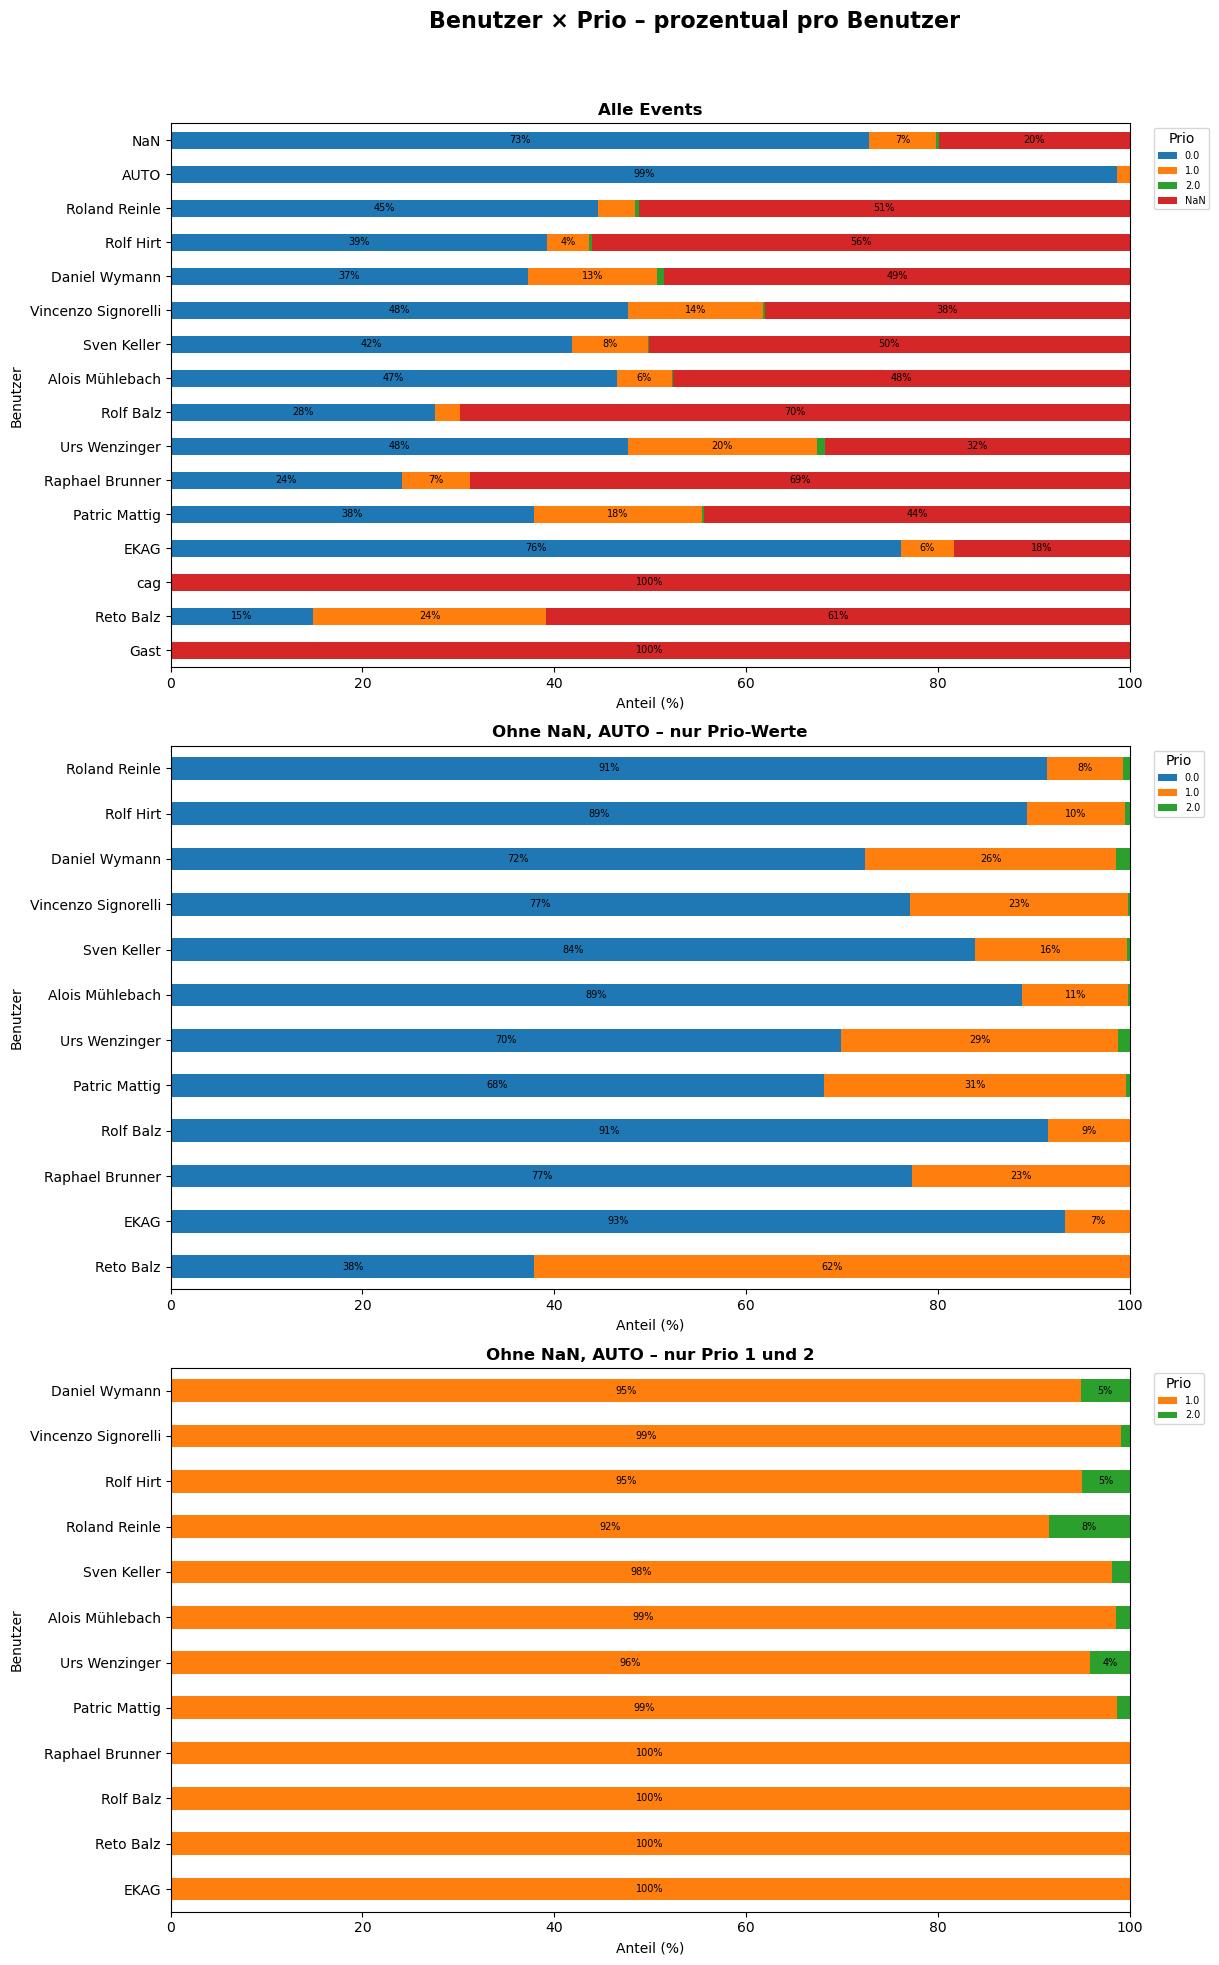

In [11]:
all_prios = sorted(df["Prio"].dropna().unique())
all_prios_str = [str(p) for p in all_prios] + ["NaN"]
cmap_prio = plt.cm.tab10
prio_colors = {p: cmap_prio(i) for i, p in enumerate(all_prios_str)}

df_no_nan_auto = df[(df["Benutzer"].notna()) & (~df["Benutzer"].isin(["AUTO"]))]

fig, axes = plt.subplots(3, 1, figsize=(14, 20))

datasets = [
    (df, "Alle Events", True, None),
    (df_no_nan_auto, "Ohne NaN, AUTO – nur Prio-Werte", False, None),
    (df_no_nan_auto, "Ohne NaN, AUTO – nur Prio 1 und 2", False, ["1.0", "2.0"])
]

for ax, (data, title, include_nan, only_prios) in zip(axes, datasets):
    ct = pd.crosstab(data["Benutzer"].fillna("NaN"), data["Prio"].fillna("NaN"))
    ct.columns = [str(c) for c in ct.columns]

    if include_nan:
        cols = [c for c in all_prios_str if c in ct.columns]
    else:
        cols = [c for c in all_prios_str if c in ct.columns and c != "NaN"]
        ct = ct[cols]

    if only_prios:
        cols = [c for c in cols if c in only_prios]
        ct = ct[[c for c in cols if c in ct.columns]]

    ct = ct.reindex(columns=cols, fill_value=0)
    # Zeilen ohne Werte entfernen
    ct = ct[ct.sum(axis=1) > 0]
    user_order = ct.sum(axis=1).sort_values(ascending=True).index

    ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100
    ct_norm.loc[user_order].plot(
        kind="barh", stacked=True, ax=ax,
        color=[prio_colors[c] for c in ct.columns]
    )
    for container in ax.containers:
        lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
        ax.bar_label(container, labels=lbl, label_type="center", fontsize=7)
    ax.set_xlabel("Anteil (%)")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.legend(title="Prio", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)

plt.suptitle("Benutzer × Prio – prozentual pro Benutzer",
             fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 0.88, 0.96])
plt.show()

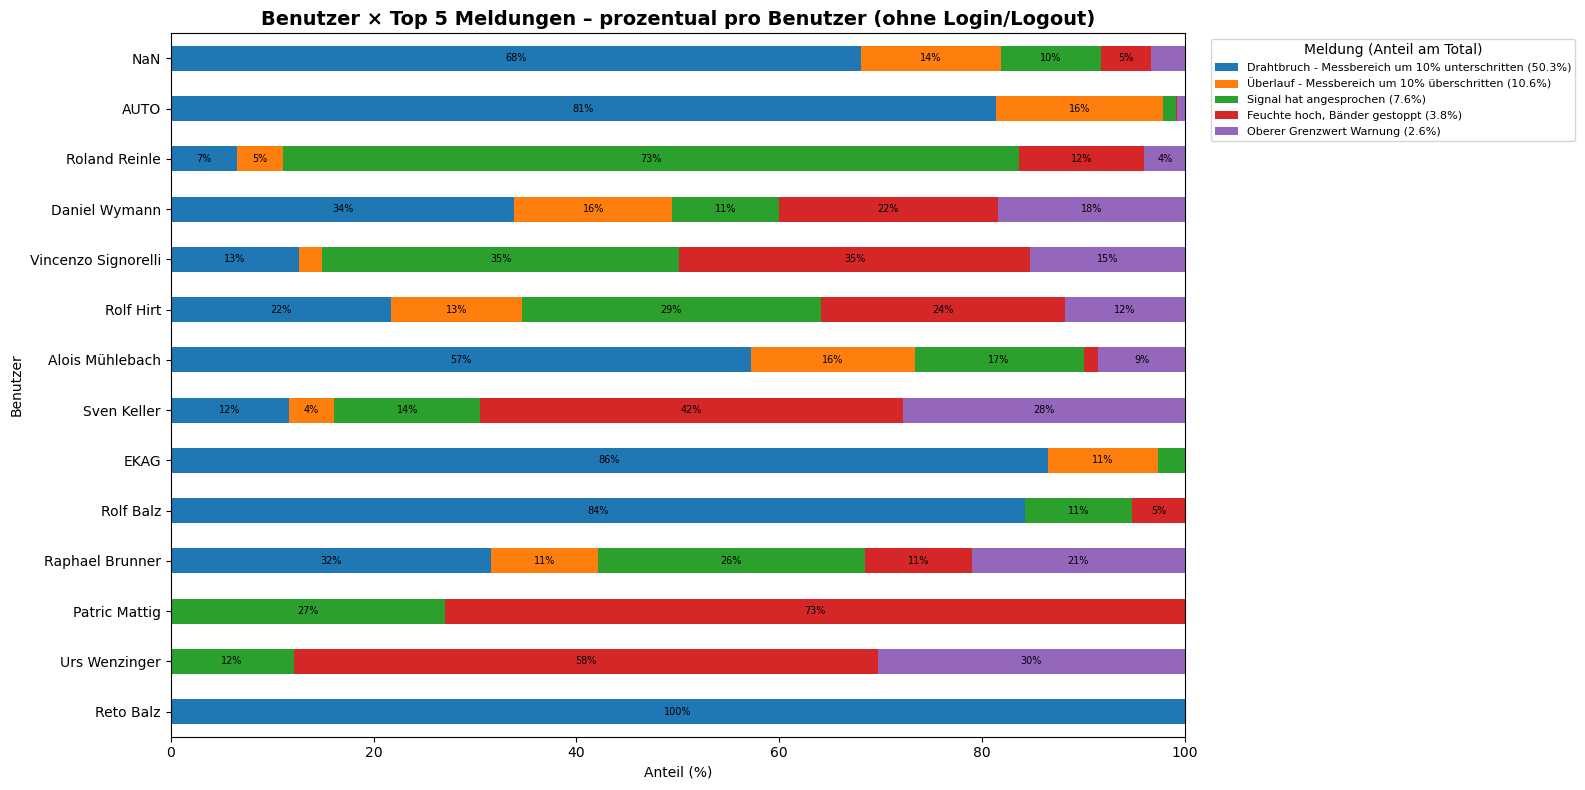

In [12]:
df_no_ll = df[df["evtTyp"] != "Login/Logout"]
top5_meldungen = df_no_ll["Meldung"].value_counts().head(5).index.tolist()
total_meldungen = df_no_ll["Meldung"].count()
meld_pct = {m: (df_no_ll["Meldung"].value_counts()[m] / total_meldungen * 100) for m in top5_meldungen}

cmap_meld = plt.cm.tab10
meld_colors = {m: cmap_meld(i) for i, m in enumerate(top5_meldungen)}

fig, ax = plt.subplots(1, 1, figsize=(16, 8))

data = df_no_ll[df_no_ll["Meldung"].isin(top5_meldungen)]
ct = pd.crosstab(data["Benutzer"].fillna("NaN"), data["Meldung"])
ct = ct.reindex(columns=[m for m in top5_meldungen if m in ct.columns], fill_value=0)
ct = ct[ct.sum(axis=1) > 0]
user_order = ct.sum(axis=1).sort_values(ascending=True).index

ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100
ct_norm.loc[user_order].plot(
    kind="barh", stacked=True, ax=ax,
    color=[meld_colors[c] for c in ct.columns]
)
for container in ax.containers:
    lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
    ax.bar_label(container, labels=lbl, label_type="center", fontsize=7)
ax.set_xlabel("Anteil (%)")

legend_labels = [f"{m} ({meld_pct[m]:.1f}%)" for m in ct.columns]
ax.legend(legend_labels, title="Meldung (Anteil am Total)",
          bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

ax.set_title("Benutzer × Top 5 Meldungen – prozentual pro Benutzer (ohne Login/Logout)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

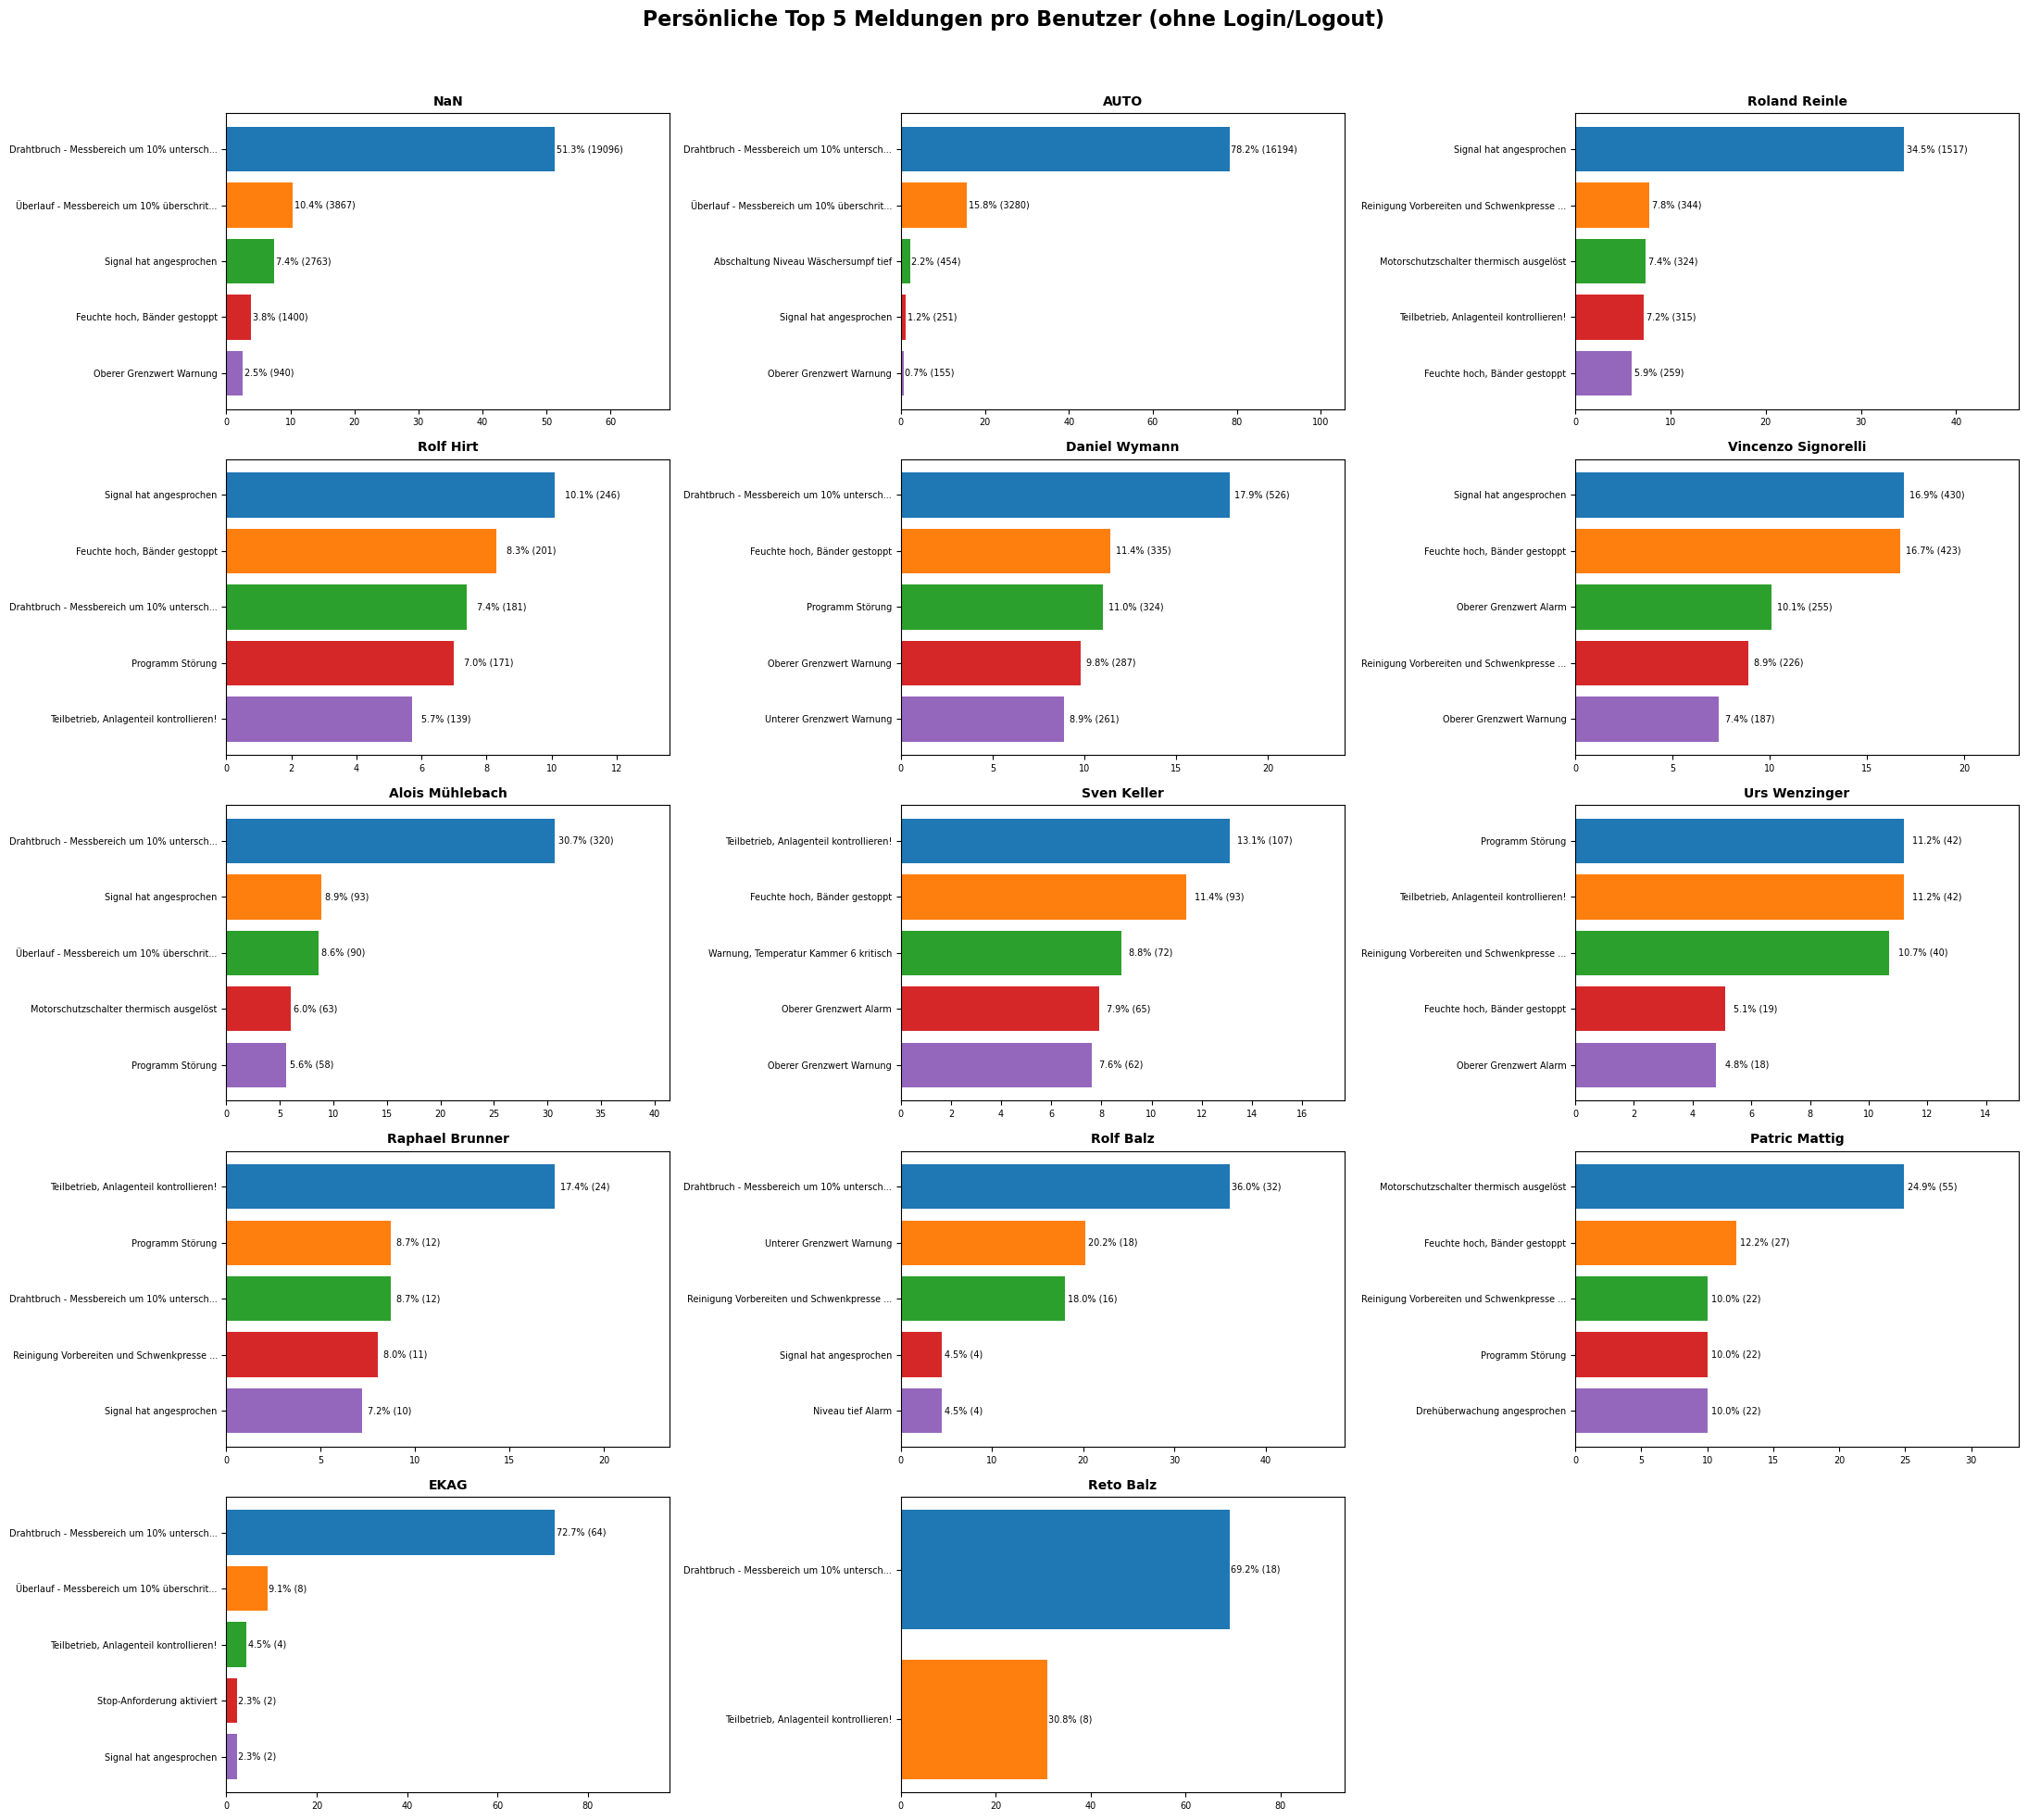

In [13]:
df_no_ll = df[df["evtTyp"] != "Login/Logout"]
benutzer_list = df_no_ll["Benutzer"].fillna("NaN").value_counts().index.tolist()

n_users = len(benutzer_list)
cols = 3
rows = (n_users + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(22, 4 * rows))
axes = axes.flatten()

for i, user in enumerate(benutzer_list):
    ax = axes[i]
    if user == "NaN":
        user_data = df_no_ll[df_no_ll["Benutzer"].isna()]
    else:
        user_data = df_no_ll[df_no_ll["Benutzer"] == user]
    
    top5 = user_data["Meldung"].value_counts().head(5)
    total = user_data["Meldung"].count()
    top5_pct = (top5 / total * 100).round(1)

    labels = [m[:40] + "..." if len(m) > 40 else m for m in top5.index]

    colors = plt.cm.tab10(range(len(top5)))
    bars = ax.barh(range(len(top5)), top5_pct.values, color=colors)
    ax.set_yticks(range(len(top5)))
    ax.set_yticklabels(labels, fontsize=7)
    ax.invert_yaxis()
    ax.set_xlim(0, max(top5_pct.values) * 1.35)

    for bar, pct, cnt in zip(bars, top5_pct.values, top5.values):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                f"{pct}% ({cnt})", va="center", fontsize=7)

    ax.set_title(user, fontsize=10, fontweight="bold")
    ax.tick_params(axis="x", labelsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Persönliche Top 5 Meldungen pro Benutzer (ohne Login/Logout)",
             fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

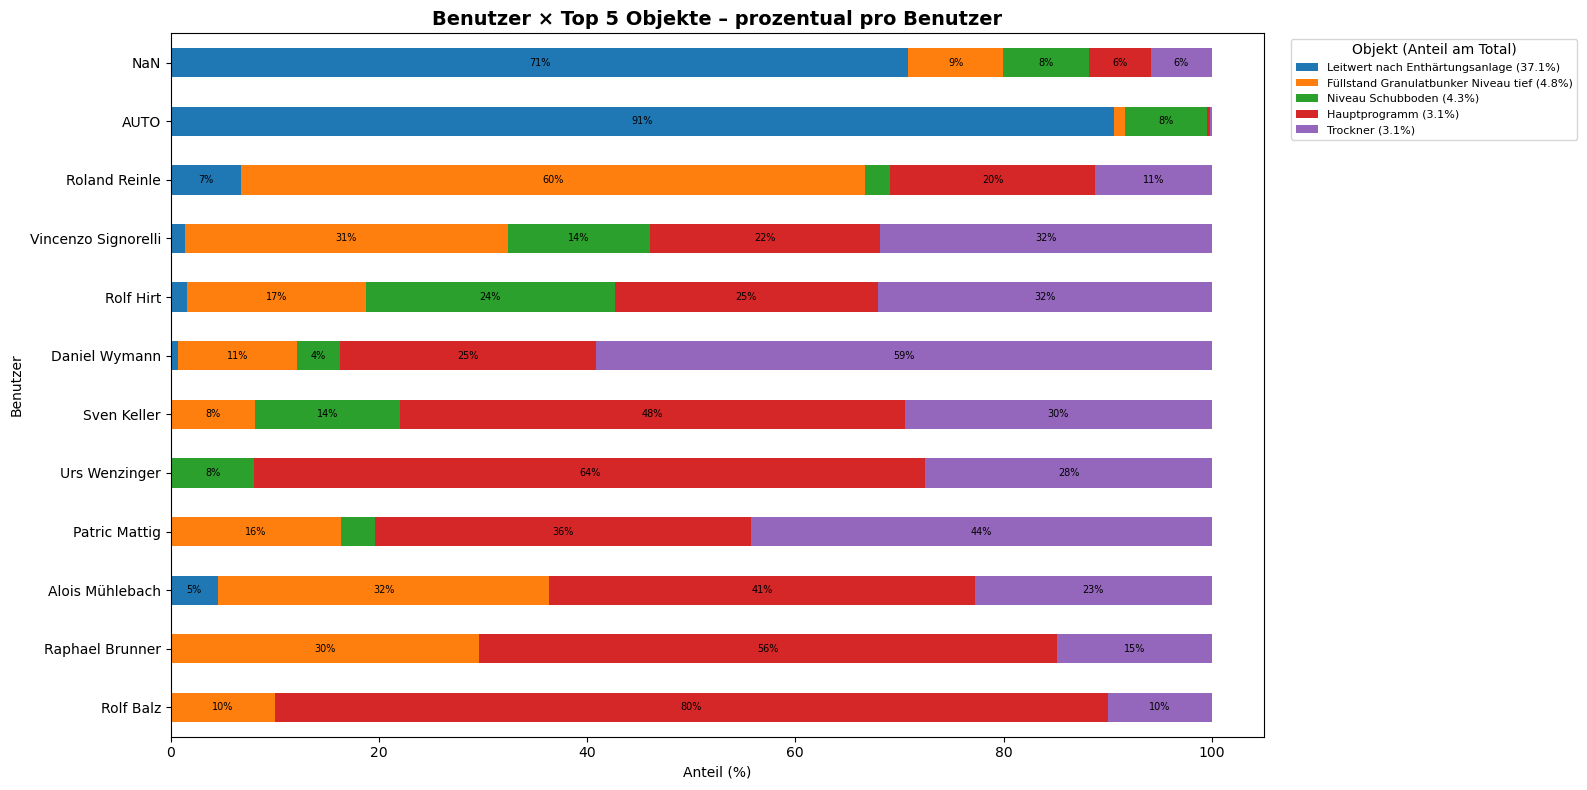

In [14]:
# === Plot 1: Top 5 Objekte ===
top5_objekte = df["Objekt"].value_counts().head(5).index.tolist()
total_objekte = df["Objekt"].count()
obj_pct = {o: (df["Objekt"].value_counts()[o] / total_objekte * 100) for o in top5_objekte}

cmap_obj = plt.cm.tab10
obj_colors = {o: cmap_obj(i) for i, o in enumerate(top5_objekte)}

fig, ax = plt.subplots(1, 1, figsize=(16, 8))

data = df[df["Objekt"].isin(top5_objekte)]
ct = pd.crosstab(data["Benutzer"].fillna("NaN"), data["Objekt"])
ct = ct.reindex(columns=[o for o in top5_objekte if o in ct.columns], fill_value=0)
ct = ct[ct.sum(axis=1) > 0]
user_order = ct.sum(axis=1).sort_values(ascending=True).index

ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100
ct_norm.loc[user_order].plot(
    kind="barh", stacked=True, ax=ax,
    color=[obj_colors[c] for c in ct.columns]
)
for container in ax.containers:
    lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
    ax.bar_label(container, labels=lbl, label_type="center", fontsize=7)
ax.set_xlabel("Anteil (%)")

legend_labels = [f"{o} ({obj_pct[o]:.1f}%)" for o in ct.columns]
ax.legend(legend_labels, title="Objekt (Anteil am Total)",
          bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

ax.set_title("Benutzer × Top 5 Objekte – prozentual pro Benutzer",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

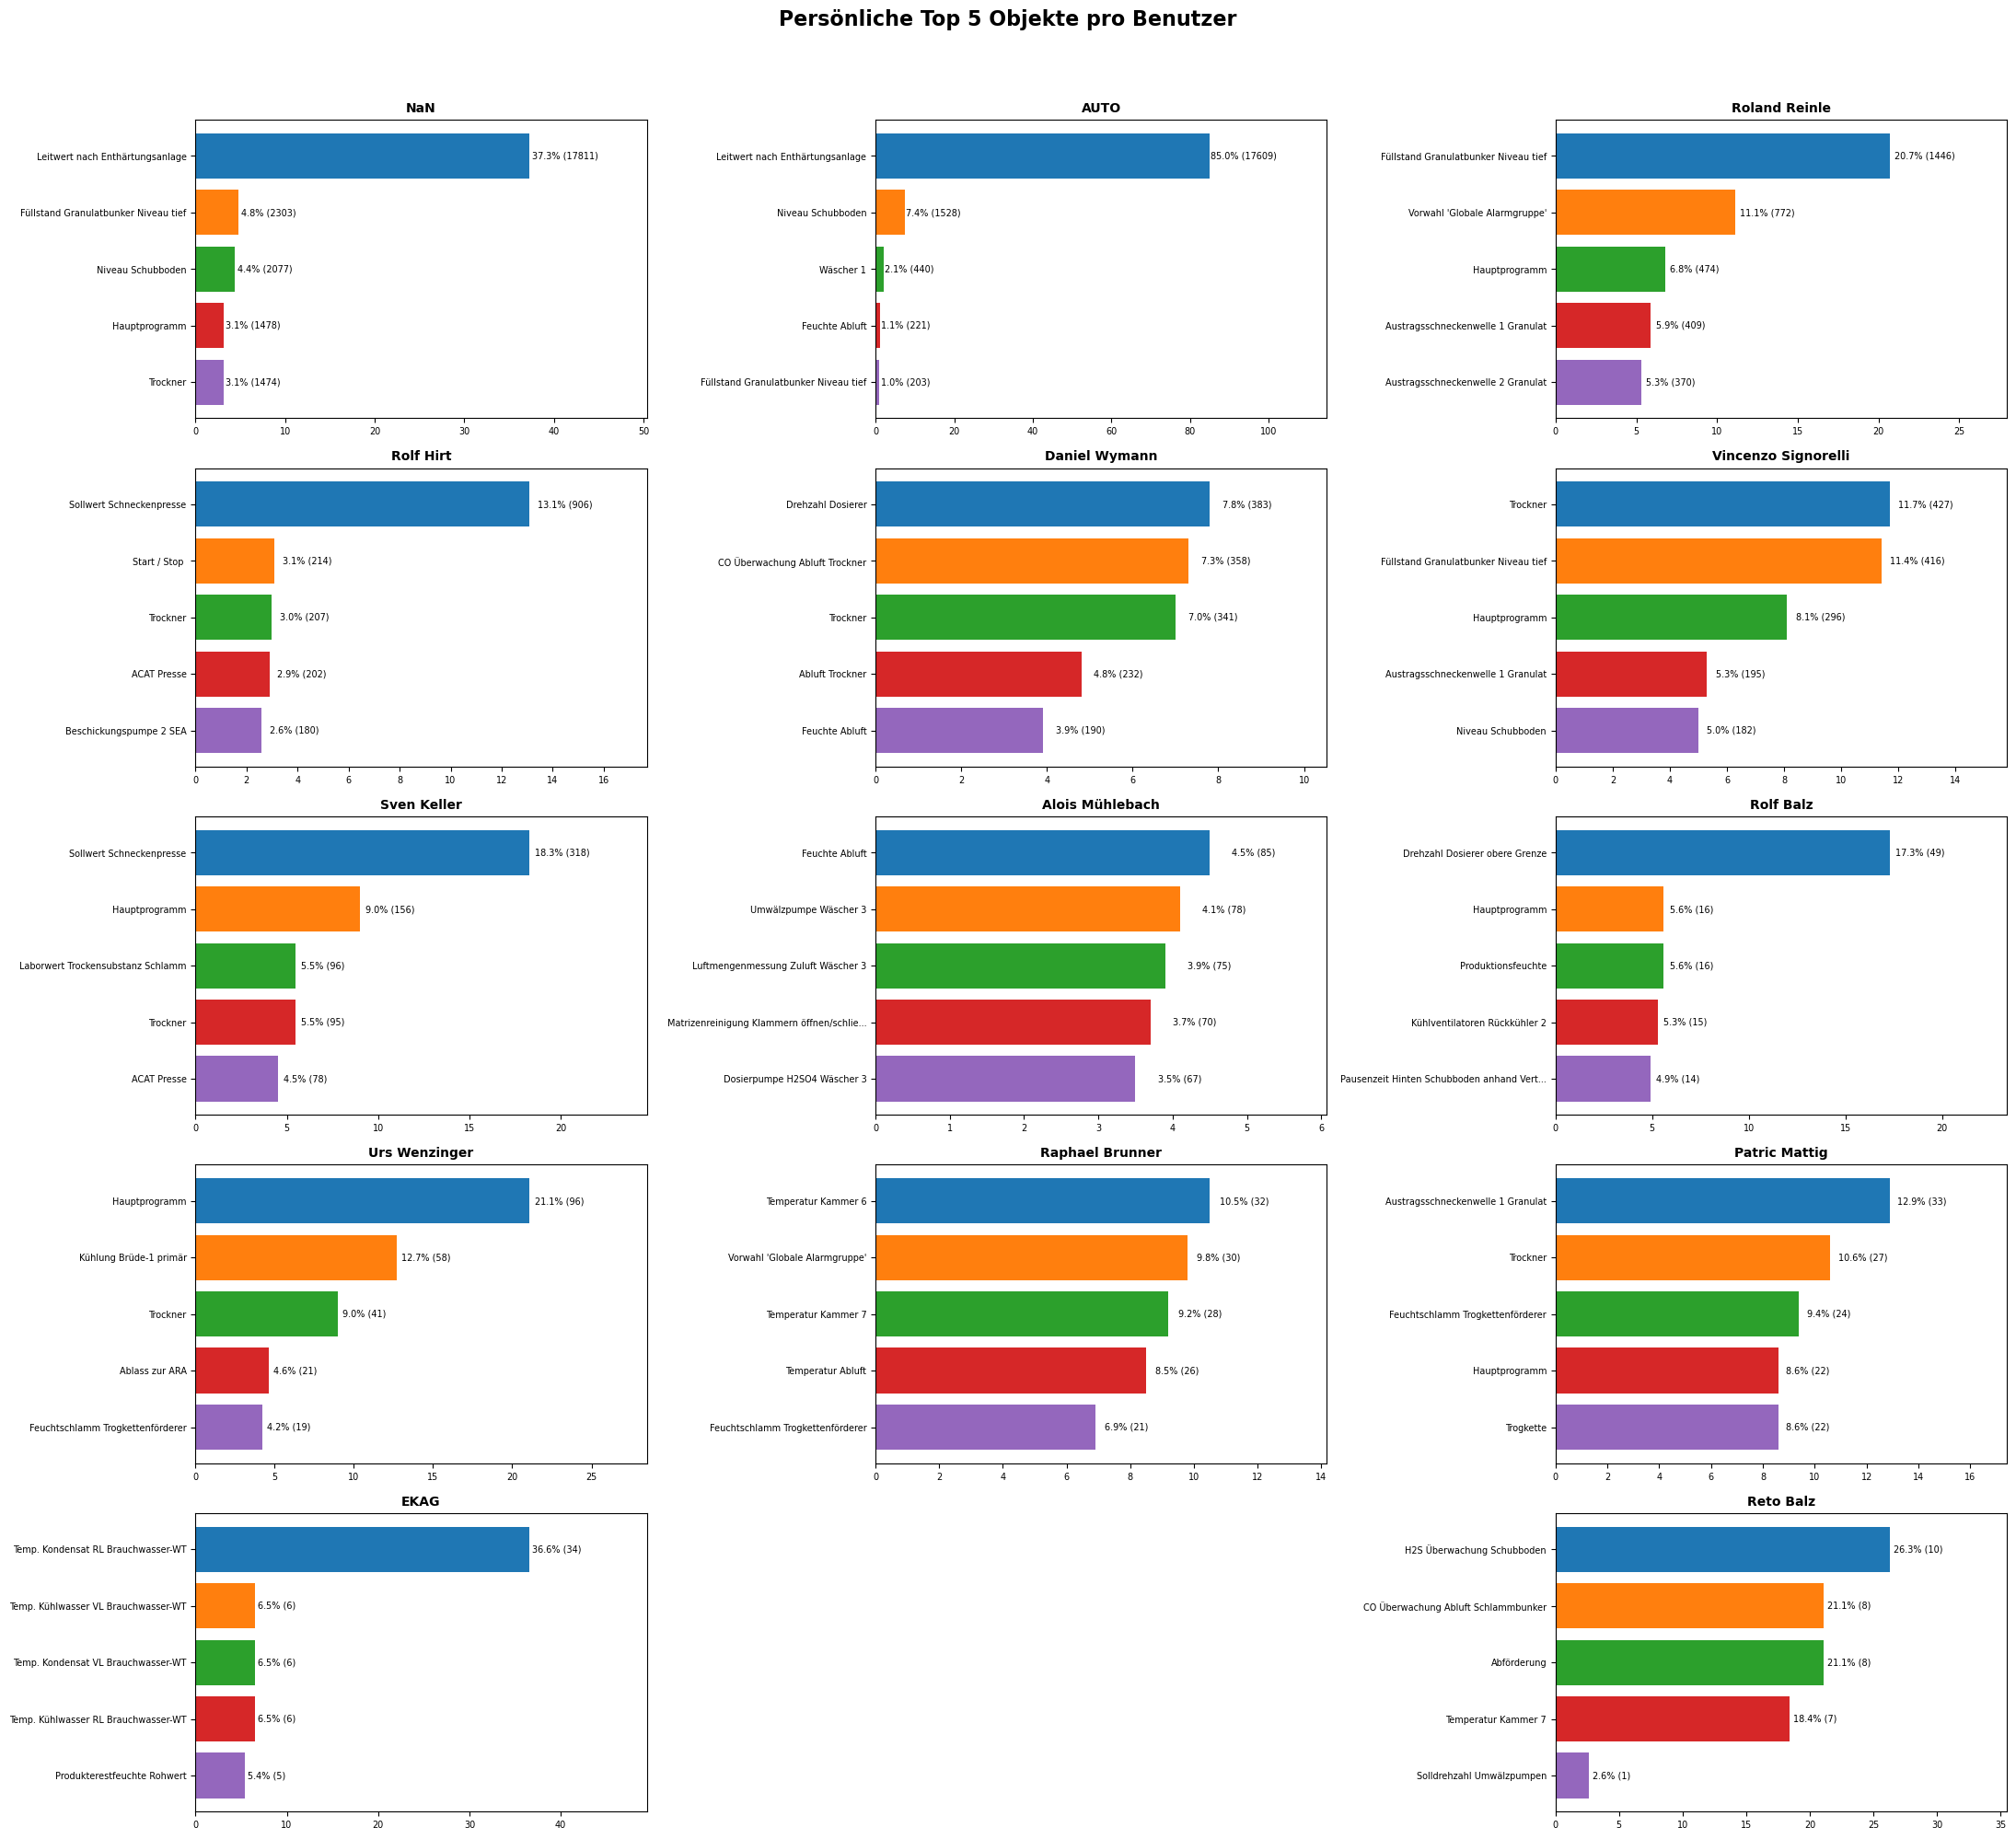

In [15]:
benutzer_list = df["Benutzer"].fillna("NaN").value_counts().index.tolist()

n_users = len(benutzer_list)
cols = 3
rows = (n_users + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(22, 4 * rows))
axes = axes.flatten()

# Zuerst alle ausblenden
for ax in axes:
    ax.set_visible(False)

for i, user in enumerate(benutzer_list):
    ax = axes[i]
    ax.set_visible(True)
    if user == "NaN":
        user_data = df[df["Benutzer"].isna()]
    else:
        user_data = df[df["Benutzer"] == user]

    top5 = user_data["Objekt"].dropna().value_counts().head(5)
    
    if len(top5) == 0:
        ax.set_visible(False)
        continue
    
    total = user_data["Objekt"].count()
    top5_pct = (top5 / total * 100).round(1)

    labels = [o[:40] + "..." if len(o) > 40 else o for o in top5.index]

    colors = plt.cm.tab10(range(len(top5)))
    bars = ax.barh(range(len(top5)), top5_pct.values, color=colors)
    ax.set_yticks(range(len(top5)))
    ax.set_yticklabels(labels, fontsize=7)
    ax.invert_yaxis()
    ax.set_xlim(0, max(top5_pct.values) * 1.35)

    for bar, pct, cnt in zip(bars, top5_pct.values, top5.values):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                f"{pct}% ({cnt})", va="center", fontsize=7)

    ax.set_title(user, fontsize=10, fontweight="bold")
    ax.tick_params(axis="x", labelsize=7)

fig.suptitle("Persönliche Top 5 Objekte pro Benutzer",
             fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

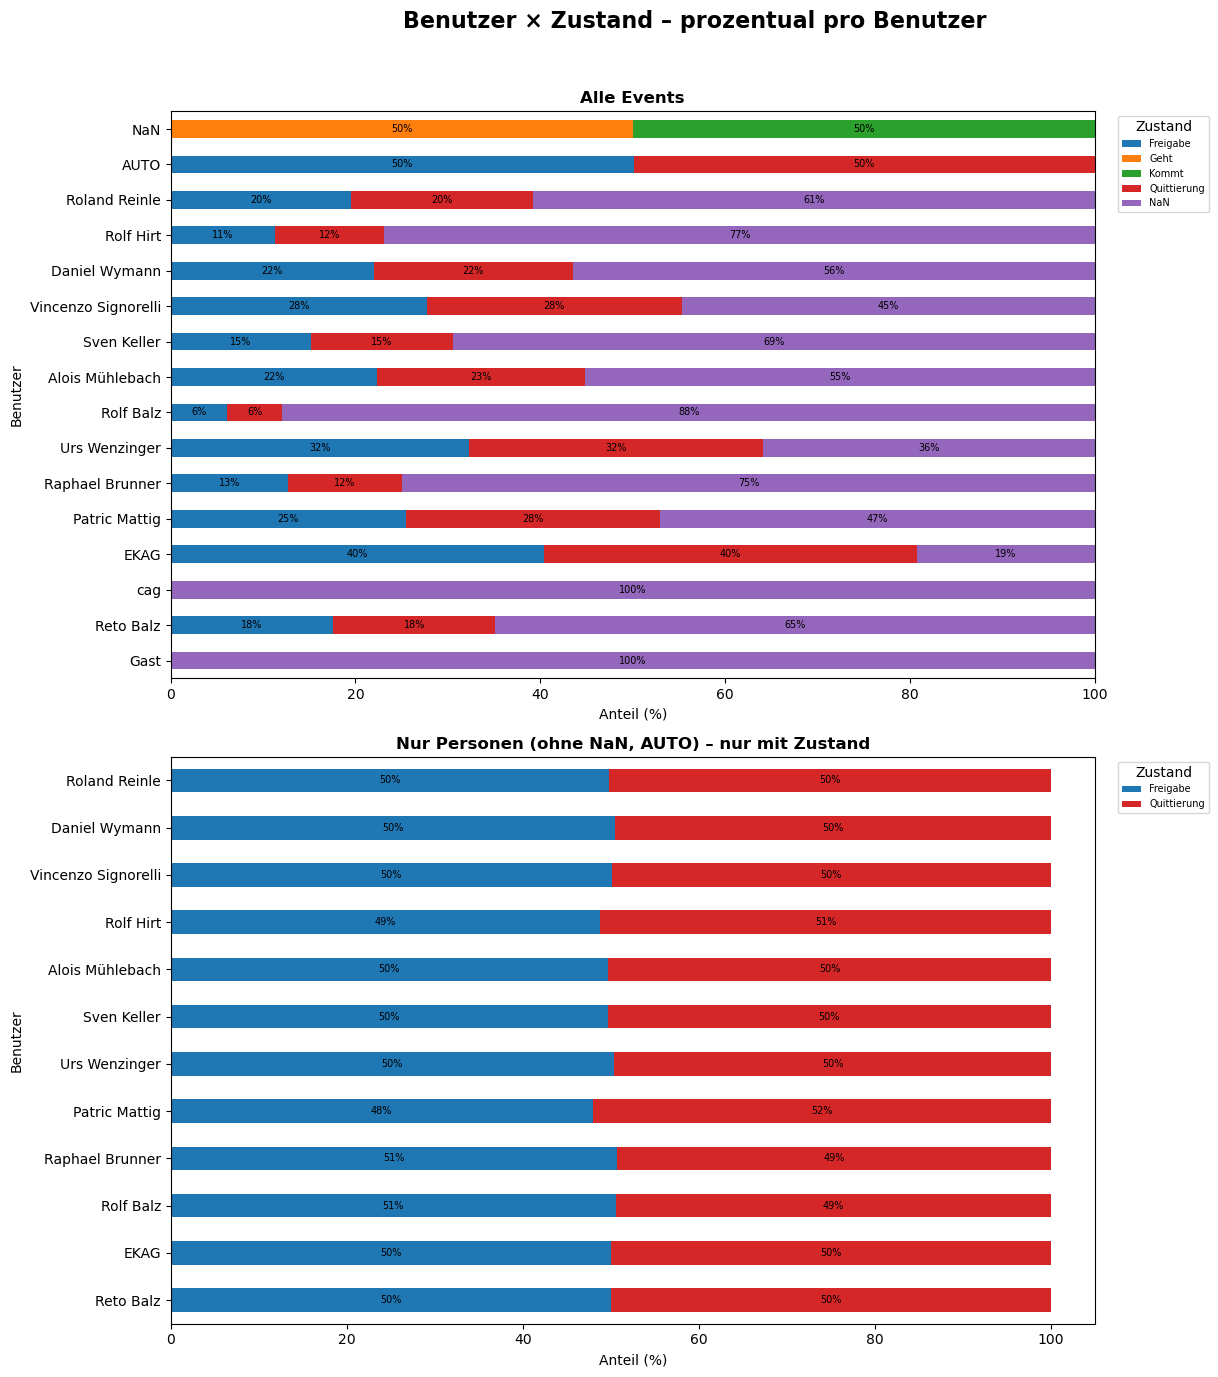

In [16]:
# Globale Zustand-Farben
all_zustaende = sorted(df["Zustand"].dropna().unique()) + ["NaN"]
cmap_zust = plt.cm.tab10
zust_colors = {z: cmap_zust(i) for i, z in enumerate(all_zustaende)}

fig, axes = plt.subplots(2, 1, figsize=(14, 14))

datasets = [
    (df, "Alle Events", True),
    (df[(df["Benutzer"].notna()) & (~df["Benutzer"].isin(["AUTO"])) & (df["Zustand"].notna())],
     "Nur Personen (ohne NaN, AUTO) – nur mit Zustand", False)
]

for ax, (data, title, include_nan) in zip(axes, datasets):
    ct = pd.crosstab(data["Benutzer"].fillna("NaN"), data["Zustand"].fillna("NaN"))
    ct.columns = [str(c) for c in ct.columns]

    if include_nan:
        cols = [c for c in all_zustaende if c in ct.columns]
    else:
        cols = [c for c in all_zustaende if c in ct.columns and c != "NaN"]
        ct = ct[cols]

    ct = ct.reindex(columns=cols, fill_value=0)
    ct = ct[ct.sum(axis=1) > 0]
    user_order = ct.sum(axis=1).sort_values(ascending=True).index

    ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100
    ct_norm.loc[user_order].plot(
        kind="barh", stacked=True, ax=ax,
        color=[zust_colors[c] for c in ct.columns]
    )
    for container in ax.containers:
        lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
        ax.bar_label(container, labels=lbl, label_type="center", fontsize=7)
    ax.set_xlabel("Anteil (%)")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.legend(title="Zustand", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)

plt.suptitle("Benutzer × Zustand – prozentual pro Benutzer",
             fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 0.88, 0.96])
plt.show()

In [17]:
# === Datum vorbereiten ===
df["Datum"] = pd.to_datetime(df["Datum"])
df["Stunde"] = df["Datum"].dt.hour
df["Wochentag"] = df["Datum"].dt.day_name()
df["Wochentag_Nr"] = df["Datum"].dt.dayofweek
df["Tag"] = df["Datum"].dt.date
df["Woche"] = df["Datum"].dt.isocalendar().week.astype(int)
df["Monat"] = df["Datum"].dt.to_period("M")

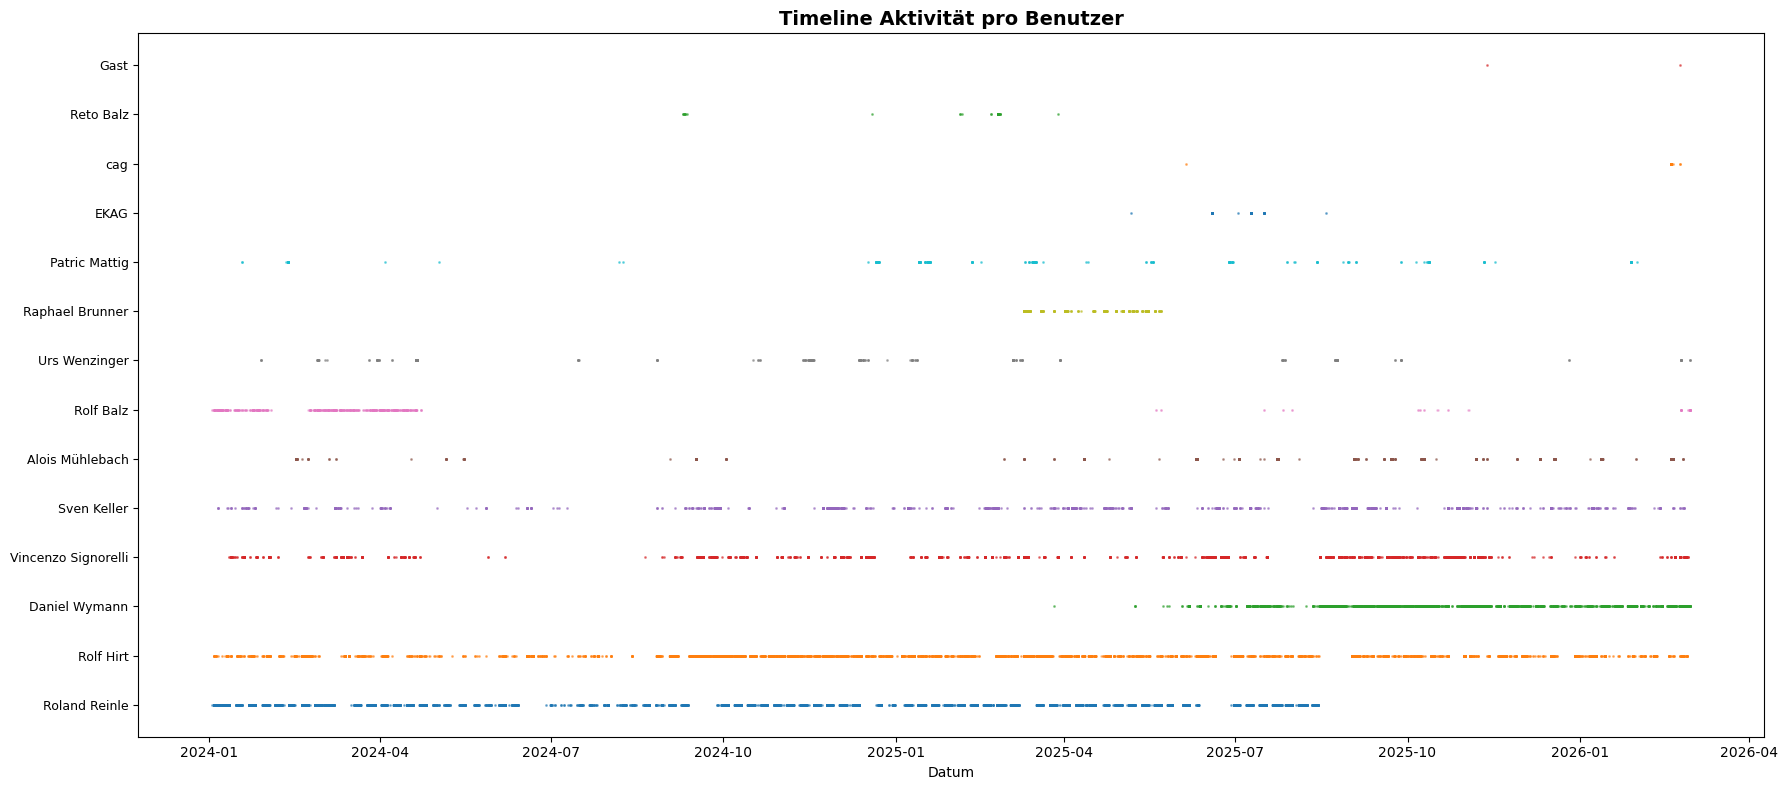

In [18]:
# === 1. Timeline Aktivität pro Benutzer ===
df_persons = df[(df["Benutzer"].notna()) & (~df["Benutzer"].isin(["AUTO"]))]
benutzer_sorted = df_persons["Benutzer"].value_counts().index.tolist()

fig, ax = plt.subplots(figsize=(18, 8))
for i, user in enumerate(benutzer_sorted):
    user_data = df_persons[df_persons["Benutzer"] == user]
    ax.scatter(user_data["Datum"], [i] * len(user_data), s=1, alpha=0.3, label=user)

ax.set_yticks(range(len(benutzer_sorted)))
ax.set_yticklabels(benutzer_sorted, fontsize=9)
ax.set_xlabel("Datum")
ax.set_title("Timeline Aktivität pro Benutzer", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

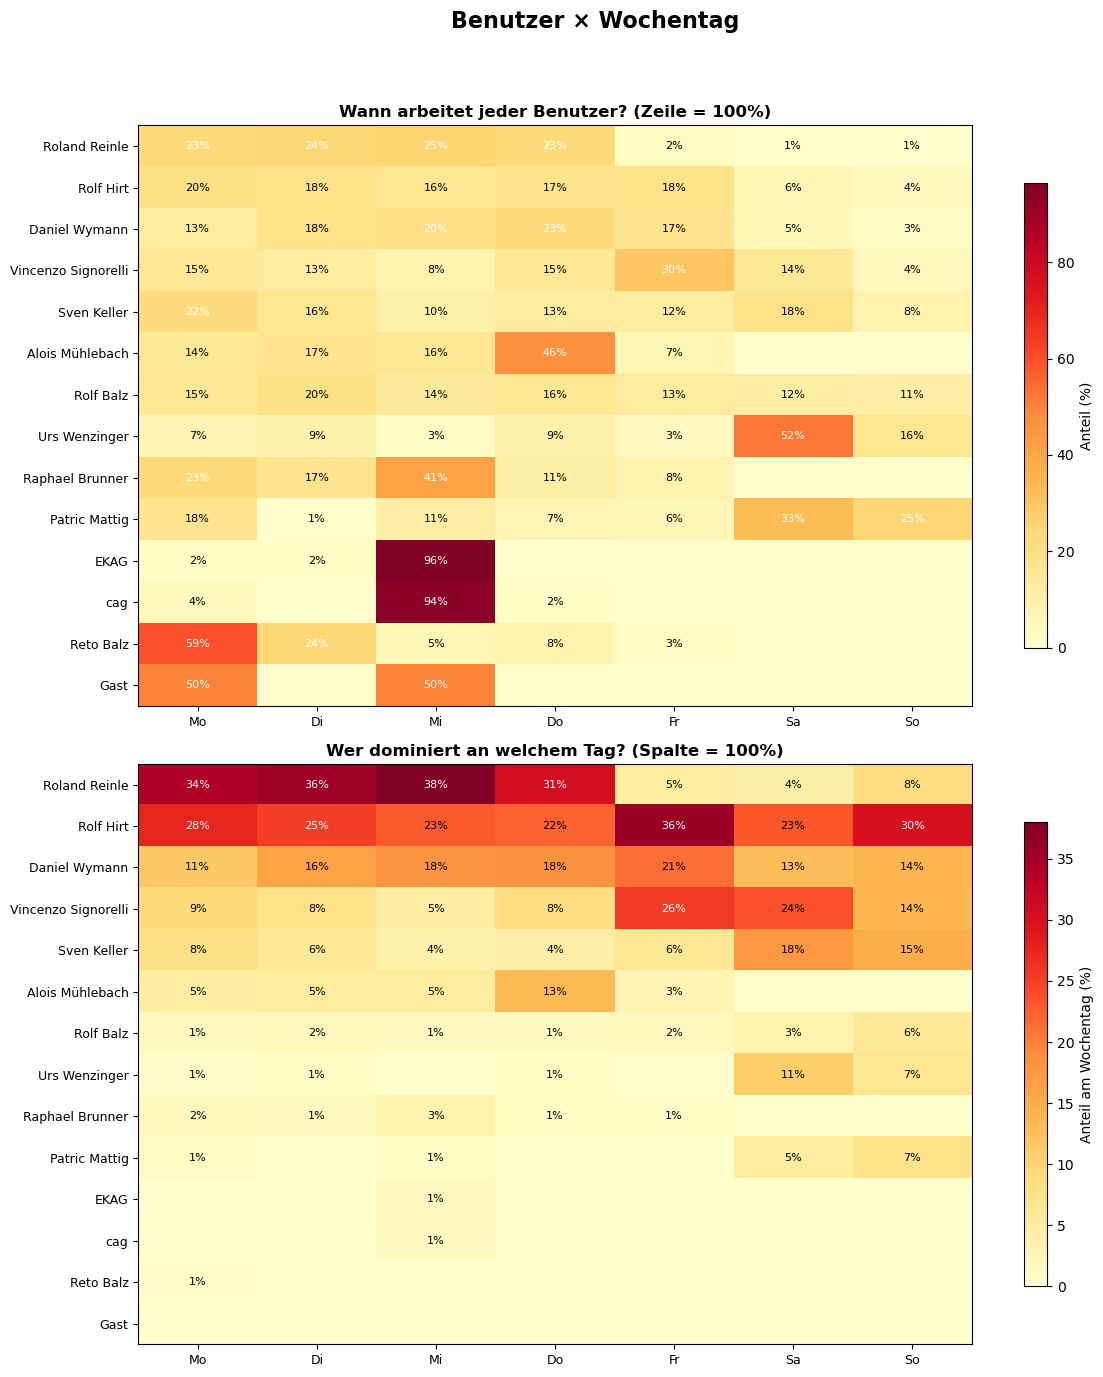

In [20]:
wochentag_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wochentag_labels = ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"]

df["Datum"] = pd.to_datetime(df["Datum"])
df["Wochentag"] = df["Datum"].dt.day_name()
df["Stunde"] = df["Datum"].dt.hour

df_persons = df[(df["Benutzer"].notna()) & (~df["Benutzer"].isin(["AUTO"]))]

fig, axes = plt.subplots(2, 1, figsize=(12, 14))

# === Oben: Pro Zeile (Wann arbeite ich?) ===
ct = pd.crosstab(df_persons["Benutzer"], df_persons["Wochentag"])
ct = ct.reindex(columns=wochentag_order, fill_value=0)
ct.columns = wochentag_labels
user_order = ct.sum(axis=1).sort_values(ascending=False).index
ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100

im1 = axes[0].imshow(ct_norm.loc[user_order].values, cmap="YlOrRd", aspect="auto")
axes[0].set_yticks(range(len(user_order)))
axes[0].set_yticklabels(user_order, fontsize=9)
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(wochentag_labels, fontsize=9)

for i in range(len(user_order)):
    for j in range(7):
        val = ct_norm.loc[user_order].iloc[i, j]
        if val >= 0.5:
            color = "white" if val > 20 else "black"
            axes[0].text(j, i, f"{val:.0f}%", ha="center", va="center", fontsize=8, color=color)

cbar1 = plt.colorbar(im1, ax=axes[0], shrink=0.8)
cbar1.set_label("Anteil (%)")
axes[0].set_title("Wann arbeitet jeder Benutzer? (Zeile = 100%)",
                   fontsize=12, fontweight="bold")

# === Unten: Pro Spalte (Wer dominiert wann?) ===
ct_norm_col = ct.div(ct.sum(axis=0), axis=1) * 100

im2 = axes[1].imshow(ct_norm_col.loc[user_order].values, cmap="YlOrRd", aspect="auto")
axes[1].set_yticks(range(len(user_order)))
axes[1].set_yticklabels(user_order, fontsize=9)
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(wochentag_labels, fontsize=9)

for i in range(len(user_order)):
    for j in range(7):
        val = ct_norm_col.loc[user_order].iloc[i, j]
        if val >= 0.5:
            color = "white" if val > 25 else "black"
            axes[1].text(j, i, f"{val:.0f}%", ha="center", va="center", fontsize=8, color=color)

cbar2 = plt.colorbar(im2, ax=axes[1], shrink=0.8)
cbar2.set_label("Anteil am Wochentag (%)")
axes[1].set_title("Wer dominiert an welchem Tag? (Spalte = 100%)",
                   fontsize=12, fontweight="bold")

plt.suptitle("Benutzer × Wochentag", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

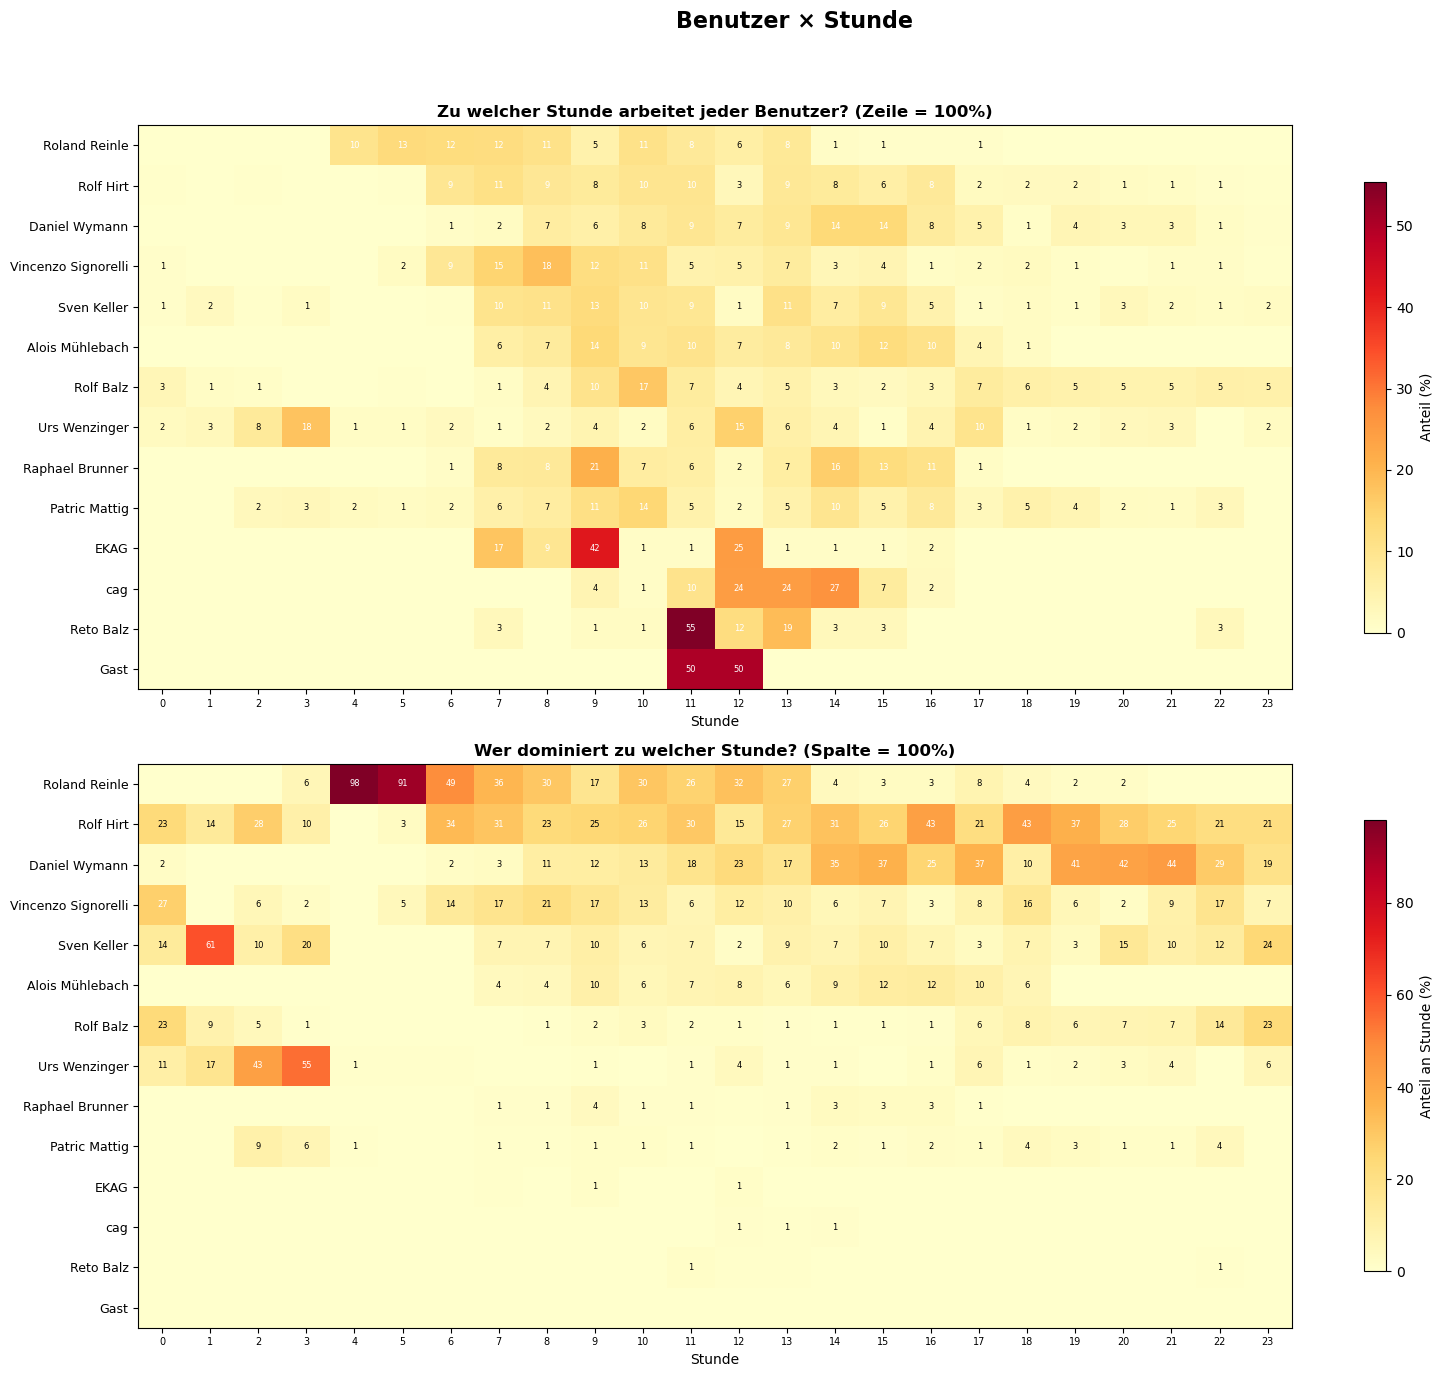

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(16, 14))

# === Oben: Pro Zeile (Wann arbeite ich?) ===
ct = pd.crosstab(df_persons["Benutzer"], df_persons["Stunde"])
ct = ct.reindex(columns=range(24), fill_value=0)
user_order = ct.sum(axis=1).sort_values(ascending=False).index
ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100

im1 = axes[0].imshow(ct_norm.loc[user_order].values, cmap="YlOrRd", aspect="auto")
axes[0].set_yticks(range(len(user_order)))
axes[0].set_yticklabels(user_order, fontsize=9)
axes[0].set_xticks(range(24))
axes[0].set_xticklabels(range(24), fontsize=7)
axes[0].set_xlabel("Stunde")

for i in range(len(user_order)):
    for j in range(24):
        val = ct_norm.loc[user_order].iloc[i, j]
        if val >= 0.5:
            color = "white" if val > 8 else "black"
            axes[0].text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=6, color=color)

cbar1 = plt.colorbar(im1, ax=axes[0], shrink=0.8)
cbar1.set_label("Anteil (%)")
axes[0].set_title("Zu welcher Stunde arbeitet jeder Benutzer? (Zeile = 100%)",
                   fontsize=12, fontweight="bold")

# === Unten: Pro Spalte (Wer dominiert wann?) ===
ct_norm_col = ct.div(ct.sum(axis=0), axis=1) * 100

im2 = axes[1].imshow(ct_norm_col.loc[user_order].values, cmap="YlOrRd", aspect="auto")
axes[1].set_yticks(range(len(user_order)))
axes[1].set_yticklabels(user_order, fontsize=9)
axes[1].set_xticks(range(24))
axes[1].set_xticklabels(range(24), fontsize=7)
axes[1].set_xlabel("Stunde")

for i in range(len(user_order)):
    for j in range(24):
        val = ct_norm_col.loc[user_order].iloc[i, j]
        if val >= 0.5:
            color = "white" if val > 25 else "black"
            axes[1].text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=6, color=color)

cbar2 = plt.colorbar(im2, ax=axes[1], shrink=0.8)
cbar2.set_label("Anteil an Stunde (%)")
axes[1].set_title("Wer dominiert zu welcher Stunde? (Spalte = 100%)",
                   fontsize=12, fontweight="bold")

plt.suptitle("Benutzer × Stunde", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

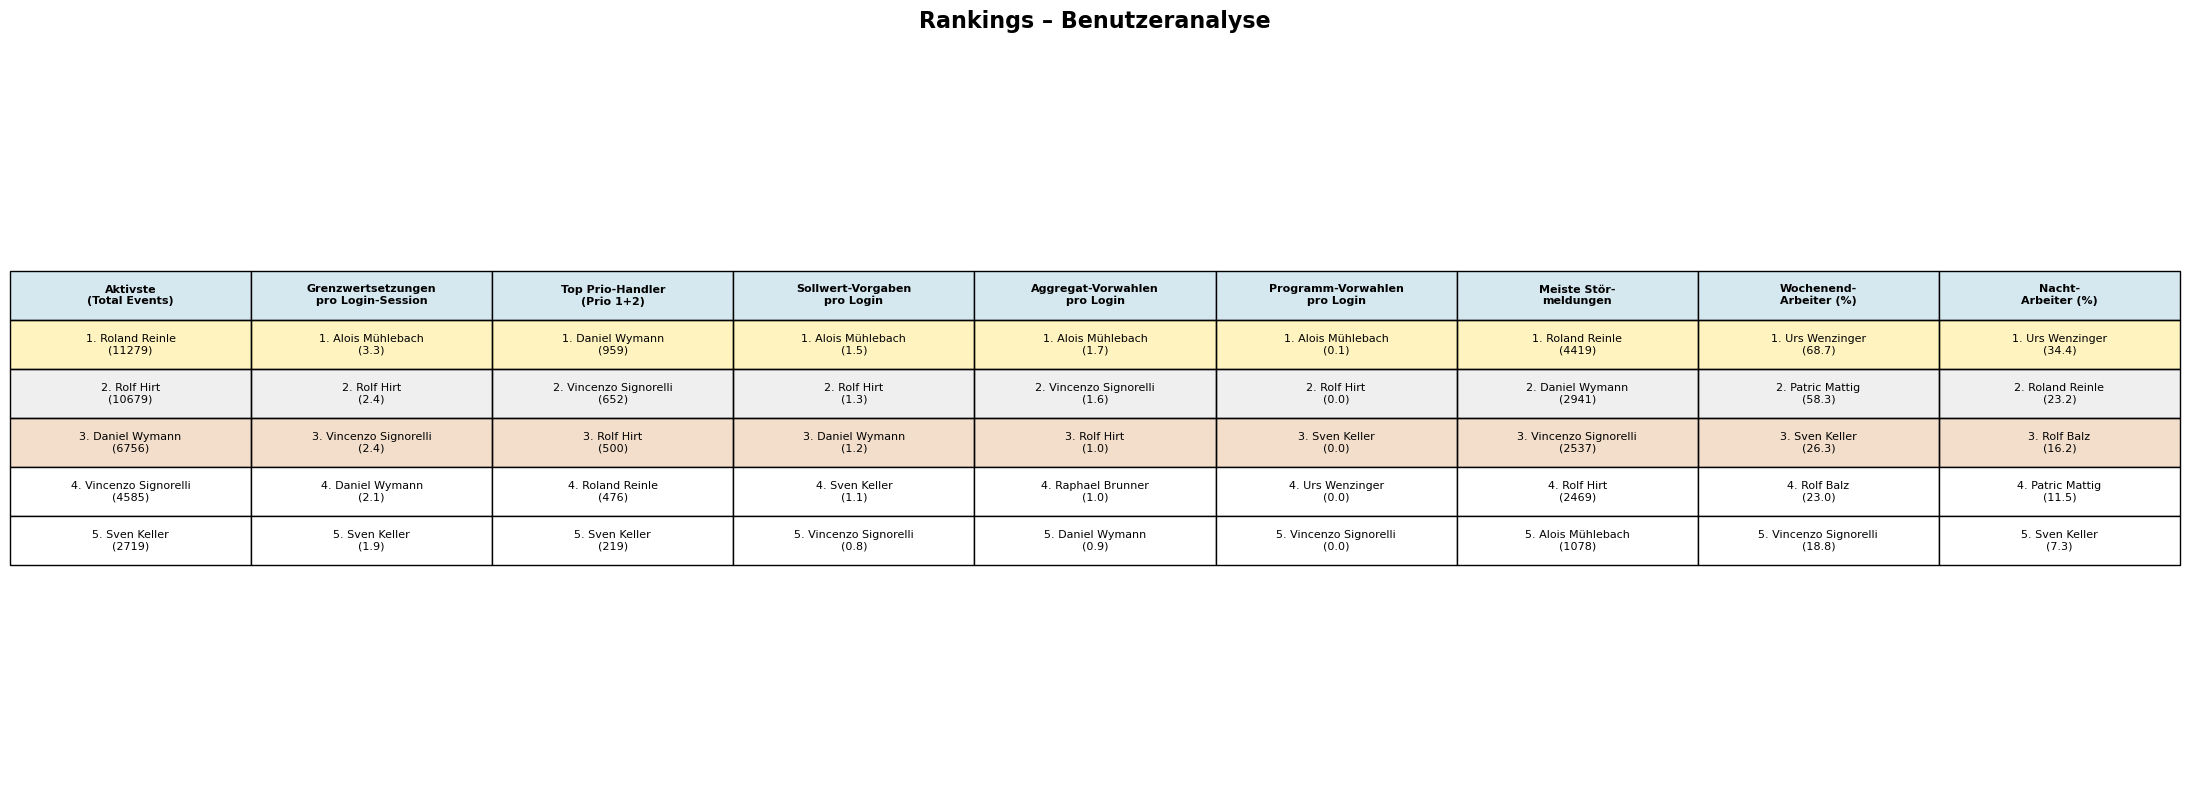

In [26]:
# === Ranking-Tabelle als Plot ===
dp = df[(df["Benutzer"].notna()) & (~df["Benutzer"].isin(["AUTO", "Gast", "cag"]))]

ll = df[df["evtTyp"] == "Login/Logout"]
logins = ll[ll["Meldung"].str.startswith("Login", na=False)]
login_counts = logins.groupby("Benutzer").size()

eingriffe = dp[dp["evtTyp"].isin(["Sollwert-Vorgaben", "Aggregate-Vorwahlen", "Programm-Vorwahlen"])]
eing_counts = eingriffe.groupby("Benutzer").size()
eff = (eing_counts / login_counts).dropna().round(2)

prio_high = dp[dp["Prio"].isin([1.0, 2.0])]
stoer = dp[dp["evtTyp"] == "Störmeldungen"]
sv = dp[dp["evtTyp"] == "Sollwert-Vorgaben"]
av = dp[dp["evtTyp"] == "Aggregate-Vorwahlen"]
pv = dp[dp["evtTyp"] == "Programm-Vorwahlen"]

sv_eff = (sv.groupby("Benutzer").size() / login_counts).dropna().round(2)
av_eff = (av.groupby("Benutzer").size() / login_counts).dropna().round(2)
pv_eff = (pv.groupby("Benutzer").size() / login_counts).dropna().round(2)

dp2 = dp.copy()
dp2["WE"] = dp2["Datum"].dt.dayofweek >= 5
dp2["Stunde"] = dp2["Datum"].dt.hour
nacht = dp2[(dp2["Stunde"] >= 22) | (dp2["Stunde"] < 6)]
we = dp2[dp2["WE"]]

we_pct = (we.groupby("Benutzer").size() / dp["Benutzer"].value_counts() * 100).round(1)
nacht_pct = (nacht.groupby("Benutzer").size() / dp["Benutzer"].value_counts() * 100).round(1)

rankings = {
    "Aktivste\n(Total Events)": dp["Benutzer"].value_counts(),
    "Grenzwertsetzungen\npro Login-Session": eff,
    "Top Prio-Handler\n(Prio 1+2)": prio_high.groupby("Benutzer").size(),
    "Sollwert-Vorgaben\npro Login": sv_eff,
    "Aggregat-Vorwahlen\npro Login": av_eff,
    "Programm-Vorwahlen\npro Login": pv_eff,
    "Meiste Stör-\nmeldungen": stoer.groupby("Benutzer").size(),
    "Wochenend-\nArbeiter (%)": we_pct,
    "Nacht-\nArbeiter (%)": nacht_pct,
}

fig, ax = plt.subplots(figsize=(22, 8))
ax.axis("off")

col_labels = list(rankings.keys())
cell_text = []

for rank in range(5):
    row = []
    for key, series in rankings.items():
        sorted_s = series.sort_values(ascending=False).dropna()
        if rank < len(sorted_s):
            name = sorted_s.index[rank]
            val = sorted_s.iloc[rank]
            if isinstance(val, float):
                row.append(f"{rank+1}. {name}\n({val:.1f})")
            else:
                row.append(f"{rank+1}. {name}\n({int(val)})")
        else:
            row.append("")
    cell_text.append(row)

table = ax.table(
    cellText=cell_text,
    colLabels=col_labels,
    cellLoc="center",
    loc="center"
)
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 2.5)

for j in range(len(col_labels)):
    table[0, j].set_text_props(fontweight="bold")
    table[0, j].set_facecolor("#D5E8F0")

medal_colors = ["#FFD700", "#C0C0C0", "#CD7F32"]
for i in range(3):
    for j in range(len(col_labels)):
        table[i+1, j].set_facecolor(medal_colors[i] + "40")

ax.set_title("Rankings – Benutzeranalyse",
             fontsize=16, fontweight="bold", pad=20)
plt.tight_layout()
plt.show()